# ProofBangla — Extended Analysis (results2/)

This notebook **adds** analyses and a few small experiments on top of the finished run of
`ProofBangla_Master_Experiments_released_models_v2.ipynb`. It must be run from the **same project folder** and the **same Python environment**.

**Safety rules (enforced in code):**
* Reads `data/unified/`, `predictions/`, `results/thresholds.json`, `results/resources.json`, `tables/` — **never writes or deletes** any of them.
* Every new file goes to `results2/` (tables, figures, JSON, CSV), to new `X_*` / `Y_*` prediction files, or to new checkpoint folders named `M4-100pct-answeronly_*`, `M4-100pct-nocontext_*`, `M3-100pct-diag-*`.
* New thresholds are written to `results2/thresholds_v2.json` (the original `results/thresholds.json` is untouched).
* **Do not re-run Stage 1.5 of the original notebook** – it deletes `predictions/F_olik_*.jsonl`. This notebook reproduces its train-set cleaning in memory only.
* No cell deletes anything. Every training/prediction step is resumable: re-run the cell after an interruption.

**Run order:** run all cells top to bottom (Kernel → Restart & Run All is fine).
Cells up to “CPU analyses” take a few minutes; the two GPU phases (grounding ablation, M3 diagnostic) take roughly 1–1.5 h in total on an 8 GB GPU. Results of the CPU phases are saved before any GPU work starts.


## Stage X0 — setup (copied from the original notebook; paths changed so that all new output goes to `results2/`)

In [1]:
# X0.1 — imports, flags, directories (new outputs -> results2/), determinism, hardware  [adapted from Stage 0.2 of the original notebook]
import os, sys
# Stage 0.2 — imports, flags, directories, determinism, hardware
import os as _os; _os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "max_split_size_mb:128,garbage_collection_threshold:0.8")   # less fragmentation (set before CUDA starts)
import gc, json, time, math, random, hashlib, re, warnings, platform, unicodedata, itertools, collections, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

SEEDS_FULL = [42, 1337, 2026]
FAST_SINGLE_SEED = False                 # True => debug with seed 42 only
SEEDS = [42] if FAST_SINGLE_SEED else SEEDS_FULL
ABLATION_SEEDS = SEEDS[:1]               # ablations that need re-training use the first seed only
FRACTIONS = [0.0, 0.10, 0.25, 1.0]
N_BOOT = 1000
LLM_EVAL_N = 600                         # stratified subset for M6 (None => full set)
SAVE_CKPT = True                         # keep fine-tuned checkpoints (fp16) for frozen transfer evals
ROOT = Path(".")
RES_OLD = ROOT / "results"                    # ORIGINAL results: read-only here
RES = ROOT / "results2"                       # every new artifact is written here
RAW, UNI, PRED, CKPT, CACHE = ROOT / "data" / "raw", ROOT / "data" / "unified", ROOT / "predictions", ROOT / "checkpoints", ROOT / "cache"
TAB, FIG = RES / "tables", RES / "figures"
for p in (RES, TAB, FIG, CKPT, CACHE):
    p.mkdir(parents=True, exist_ok=True)
assert UNI.exists() and PRED.exists() and RES_OLD.exists(), "Run this notebook from the project root (the folder that contains data/, predictions/, results/)."

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if DEVICE == "cuda" else 0.0
BF16_OK = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.bfloat16 if BF16_OK else (torch.float16 if DEVICE == "cuda" else torch.float32)
# dynamic batch sizing: (train micro-batch, infer batch) from VRAM; effective train batch is fixed at 16 by accumulation
if VRAM_GB >= 14:   TRAIN_BS, INFER_BS = 8, 32
elif VRAM_GB >= 7:  TRAIN_BS, INFER_BS = 2, 8
else:               TRAIN_BS, INFER_BS = 1, 2
EFFECTIVE_BS = 16
GRAD_CKPT = VRAM_GB < 12                 # (trainer now enables checkpointing only for large / long-context models)
LOW_VRAM = VRAM_GB < 12
GPU_CAP = 0.90 if LOW_VRAM else 1.0       # fraction of VRAM PyTorch may use
if DEVICE == "cuda" and LOW_VRAM:
    torch.cuda.set_per_process_memory_fraction(GPU_CAP, 0)   # an over-allocation raises a catchable OOM instead of spilling into system RAM
    print(f"[profile] {VRAM_GB:.1f} GB GPU: memory cap {GPU_CAP:.0%}, token-budget batching, per-epoch resume files")
print(f"device={DEVICE} gpu={torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'cpu'} vram={VRAM_GB:.1f}GB amp={AMP_DTYPE} "
      f"train_bs={TRAIN_BS} infer_bs={INFER_BS} grad_ckpt={GRAD_CKPT} seeds={SEEDS}")

def free_gpu(*objs):
    for o in objs:
        del o
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.synchronize()

[profile] 8.0 GB GPU: memory cap 90%, token-budget batching, per-epoch resume files
device=cuda gpu=NVIDIA GeForce RTX 4060 vram=8.0GB amp=torch.bfloat16 train_bs=2 infer_bs=8 grad_ckpt=True seeds=[42, 1337, 2026]


In [2]:
# X0.2 — model registry; thresholds/resources are read from results/, new ones go to results2/  [adapted from Stage 0.3]
# Stage 0.3 — model registry & global result stores
MODELS = {
    "ModernBERT":  "answerdotai/ModernBERT-base",
    "EuroBERT":    "EuroBERT/EuroBERT-210m",
    "XLM-R-base":  "xlm-roberta-base",
    "BanglaBERT-large": "csebuetnlp/banglabert_large",
}
# Released checkpoints verified against the official Hugging Face model collection.
# Note: the EuroBERT LettuceDetect releases are language-specific fine-tunes, not one
# universal "multilingual" classifier. M2 is explicitly the published Chinese RAGTruth fine-tune.
M1_CANDIDATES = ["KRLabsOrg/lettucedect-base-modernbert-en-v1"]
M2_CANDIDATES = ["KRLabsOrg/lettucedect-210m-eurobert-cn-v1"]
REQUIRE_RELEASED_M1 = True
REQUIRE_RELEASED_M2 = True
M2_SOURCE_DATASET = "KRLabsOrg/ragtruth-cn-translated"
RUN_M2STAR_SUPPLEMENTARY = False  # Enable only after released M1/M2 have been verified.
M2STAR_BACKBONE = "EuroBERT/EuroBERT-210m"
M2STAR_EPOCHS = 3
MODEL_REVISIONS = {
    "KRLabsOrg/lettucedect-base-modernbert-en-v1": "bbd77832f52f9bd87546a3924c032467921f5c34",
    "KRLabsOrg/lettucedect-210m-eurobert-cn-v1": "2ab71cb08fa068e932b5fbdbeb5e394ae8978970",
}
EUROBERT_BACKBONE_REVISION = "1babc6fa0e22d779c807ecbf93ca1aa646143a75"
EUROBERT_CODE_REVISION = "1babc6fa0e22d779c807ecbf93ca1aa646143a75"
M5_BACKBONE = "xlm-roberta-base"
M6_LLM = "Qwen/Qwen2.5-3B-Instruct"
E5_MODEL = "intfloat/multilingual-e5-base"

# thresholds / resources: the ORIGINAL files are only read; anything new is written to results2/*_v2.json
THRESHOLDS = json.loads((RES_OLD / "thresholds.json").read_text())
NEW_TAUS = {}
TAU_PATH = RES / "thresholds_v2.json"
if TAU_PATH.exists():
    NEW_TAUS.update(json.loads(TAU_PATH.read_text())); THRESHOLDS.update(NEW_TAUS)
def set_tau(key, tau):
    THRESHOLDS[key] = float(tau); NEW_TAUS[key] = float(tau); TAU_PATH.write_text(json.dumps(NEW_TAUS, indent=1))
RESOURCES = json.loads((RES_OLD / "resources.json").read_text()) if (RES_OLD / "resources.json").exists() else {}
NEW_RES = {}
RESOURCES_PATH = RES / "resources_v2.json"
if RESOURCES_PATH.exists():
    NEW_RES.update(json.loads(RESOURCES_PATH.read_text())); RESOURCES.update(NEW_RES)
def log_resource(key, peak_vram_mb):
    RESOURCES[key] = {"peak_vram_mb": float(peak_vram_mb)}; NEW_RES[key] = RESOURCES[key]; RESOURCES_PATH.write_text(json.dumps(NEW_RES, indent=1))


In [3]:
# Stage 0.4 — evaluation metrics
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, average_precision_score

def macro_f1(y, pred):
    return float(f1_score(y, pred, average="macro", zero_division=0))

def ece_score(y, p, n_bins=10):
    """Top-label ECE on P(hallucinated)=p (confidence = max(p,1-p), accuracy of argmax label)."""
    y = np.asarray(y); p = np.asarray(p, float)
    pred = (p >= 0.5).astype(int); conf = np.maximum(p, 1 - p); acc = (pred == y).astype(float)
    bins = np.linspace(0.5, 1.0, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0.5 else (conf >= lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)

def safe_auc(y, p, kind="roc"):
    y = np.asarray(y)
    if len(np.unique(y)) < 2:
        return float("nan")
    return float(roc_auc_score(y, p) if kind == "roc" else average_precision_score(y, p))

def tune_tau(y, p):
    """Threshold maximising Macro-F1 on dev."""
    y = np.asarray(y); p = np.asarray(p, float)
    cands = np.unique(np.concatenate([np.quantile(p, np.linspace(0.02, 0.98, 97)), [0.5]]))
    best, best_f = 0.5, -1
    for t in cands:
        f = macro_f1(y, (p >= t).astype(int))
        if f > best_f + 1e-12:
            best, best_f = float(t), f
    return best

def full_metrics(y, p, tau):
    y = np.asarray(y); p = np.asarray(p, float); pred = (p >= tau).astype(int)
    return dict(macro_f1=macro_f1(y, pred),
                precision=float(precision_score(y, pred, zero_division=0)),
                recall=float(recall_score(y, pred, zero_division=0)),
                auroc=safe_auc(y, p, "roc"), auprc=safe_auc(y, p, "pr"),
                ece=ece_score(y, p), accuracy=float((pred == y).mean()), n=int(len(y)))

def _macro_f1_batch(y, pred):
    """Vectorised macro-F1 for arrays shaped (B,N)."""
    f = 0.0
    for c in (0, 1):
        tp = ((pred == c) & (y == c)).sum(1); fp = ((pred == c) & (y != c)).sum(1); fn = ((pred != c) & (y == c)).sum(1)
        d = 2 * tp + fp + fn
        f = f + np.where(d > 0, 2 * tp / np.maximum(d, 1), 0.0)
    return f / 2

def boot_indices(n, B=N_BOOT, seed=0):
    return np.random.default_rng(seed).integers(0, n, size=(B, n))

def bootstrap_ci_single(y, pred, B=N_BOOT, seed=0):
    y = np.asarray(y); pred = np.asarray(pred); idx = boot_indices(len(y), B, seed)
    s = _macro_f1_batch(y[idx], pred[idx]); return float(np.percentile(s, 2.5)), float(np.percentile(s, 97.5))

def bootstrap_ci_multiseed(y, preds_by_seed, B=N_BOOT, seed=0):
    """CI of the seed-averaged Macro-F1, resampling examples jointly across seeds."""
    y = np.asarray(y); idx = boot_indices(len(y), B, seed)
    s = np.mean([_macro_f1_batch(y[idx], np.asarray(p)[idx]) for p in preds_by_seed], axis=0)
    return float(np.percentile(s, 2.5)), float(np.percentile(s, 97.5))

In [4]:
# Stage 0.5 — CSV / LaTeX / figure export utilities
plt.style.use("seaborn-v0_8-whitegrid")
PALETTE = sns.color_palette("colorblind")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "figure.dpi": 110, "savefig.dpi": 300,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})

def _num(x):
    if isinstance(x, (int, float, np.integer, np.floating)) and not (isinstance(x, float) and math.isnan(x)):
        return float(x)
    if isinstance(x, str):
        m = re.match(r"^\s*(-?\d+(?:\.\d+)?)", x)
        if m:
            return float(m.group(1))
    return None

_TEX_MAP = [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#"), ("$", r"\$"),
            ("±", r"$\pm$"), ("Δ", r"$\Delta$"), ("χ²", r"$\chi^2$"), ("τ", r"$\tau$"), ("≥", r"$\geq$"), ("→", r"$\rightarrow$")]
def tex_escape(s):
    s = str(s)
    for a, b in _TEX_MAP:
        s = s.replace(a, b)
    return s

def _fmt_cell(x, digits=3):
    if isinstance(x, (float, np.floating)):
        return "--" if math.isnan(x) else f"{x:.{digits}f}"
    if isinstance(x, (int, np.integer)):
        return str(x)
    return "--" if x is None else str(x)

def save_table(df, name, caption, higher_better=(), lower_better=(), group_col=None, digits=3, label=None, note=None):
    """Write ./tables/<name>.csv and booktabs ./tables/<name>.tex (best bold, second-best underlined)."""
    df = df.copy().reset_index(drop=True)
    df.to_csv(TAB / f"{name}.csv", index=False)
    groups = [df.index] if group_col is None else [g.index for _, g in df.groupby(group_col, sort=False)]
    mark = {}
    for cols, hb in ((higher_better, True), (lower_better, False)):
        for col in cols:
            if col not in df.columns:
                continue
            for gi in groups:
                vals = [(i, _num(df.at[i, col])) for i in gi]
                vals = [(i, v) for i, v in vals if v is not None]
                uniq = sorted({round(v, 10) for _, v in vals}, reverse=hb)
                if len(vals) < 2 or not uniq:
                    continue
                for i, v in vals:
                    r = round(v, 10)
                    if r == uniq[0]: mark[(i, col)] = "b"
                    elif len(uniq) > 1 and r == uniq[1]: mark[(i, col)] = "u"
    cols = list(df.columns)
    lines = [r"\begin{table*}[t]" if len(cols) > 7 else r"\begin{table}[t]", r"\centering", r"\small",
             rf"\caption{{{tex_escape(caption)}}}", rf"\label{{{label or 'tab:' + name}}}",
             r"\resizebox{\linewidth}{!}{%", r"\begin{tabular}{" + "l" * 1 + "c" * (len(cols) - 1) + "}", r"\toprule",
             " & ".join(tex_escape(c) for c in cols) + r" \\", r"\midrule"]
    prev = None
    for i, row in df.iterrows():
        if group_col is not None and prev is not None and row[group_col] != prev:
            lines.append(r"\midrule")
        prev = row[group_col] if group_col is not None else None
        cells = []
        for c in cols:
            s = tex_escape(_fmt_cell(row[c], digits))
            m = mark.get((i, c))
            s = rf"\textbf{{{s}}}" if m == "b" else (rf"\underline{{{s}}}" if m == "u" else s)
            cells.append(s)
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}}"]
    if note:
        lines.append(rf"\\[2pt]\footnotesize {tex_escape(note)}")
    lines.append(r"\end{table*}" if len(cols) > 7 else r"\end{table}")
    (TAB / f"{name}.tex").write_text("\n".join(lines), encoding="utf-8")
    print(f"[table] saved {name}.csv/.tex ({len(df)} rows)")
    return df

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)
    print(f"[figure] saved {name}.png/.pdf @300dpi")

def mean_sd(vals, digits=3):
    v = np.asarray([x for x in vals if x is not None and not np.isnan(x)], float)
    if len(v) == 0: return "--"
    return f"{v.mean():.{digits}f} ± {v.std(ddof=1) if len(v) > 1 else 0.0:.{digits}f}"

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

In [5]:
# Stage 0.6 — prediction cache (idempotent / resumable)
def pred_path(exp, model, seed):
    return PRED / f"{exp}_{model}_seed{seed}.jsonl"

def save_preds(path, recs):
    tmp = Path(str(path) + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    tmp.replace(path)

def load_preds(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

class Lazy:
    """Creates an expensive scorer only on first use and always frees GPU memory on exit."""
    def __init__(self, factory, key=None):
        self.factory, self.obj, self.key = factory, None, key
    def get(self):
        if self.obj is None:
            reset_gpu()
            if torch.cuda.is_available():
                torch.cuda.reset_peak_memory_stats()
            self.obj = self.factory()
        return self.obj
    def __enter__(self): return self
    def __exit__(self, *a):
        if self.obj is not None:
            if self.key and torch.cuda.is_available():
                log_resource(self.key, torch.cuda.max_memory_allocated() / 2**20)
            elif self.key:
                log_resource(self.key, 0.0)
            self.obj = None
        free_gpu()

def cached_predict(exp, model, seed, df, lazy, tau=0.5):
    """Return per-example records; load from disk if already computed."""
    p = pred_path(exp, model, seed)
    if p.exists():
        recs = load_preds(p)
        if [r["id"] for r in recs] == [str(i) for i in df["id"]]:
            for r in recs:
                r["pred_label"] = int(r["pred_prob"] >= tau)
            return recs
    recs = lazy.get().predict(df)
    for r in recs:
        r["pred_label"] = int(r["pred_prob"] >= tau)
    save_preds(p, recs)
    return recs

def recs_arrays(recs):
    return (np.array([r["gold_label"] for r in recs], int), np.array([r["pred_prob"] for r in recs], float))

def pool_scores(token_probs, rule="max"):
    tp = np.asarray(token_probs, float)
    if tp.size == 0: return 0.0
    if rule == "max": return float(tp.max())
    k = int(rule.replace("top", "").replace("_mean", ""))
    return float(np.sort(tp)[::-1][:k].mean())

print("Stage 0 complete.")

Stage 0 complete.


In [6]:
# Stage 0.7 — GPU safety helpers (8 GB friendly)
OPTIMIZER_DEFAULT = "adamw_fused"       # "adamw_fused" (no temporary buffers) | "adamw8bit" (~2 GB less on BanglaBERT-large) | "adamw"

def reset_gpu():
    """Release everything that can be released: dead tensors, the notebook's stored exception traceback (it keeps OOM'd tensors alive!), CUDA cache."""
    for a in ("last_type", "last_value", "last_traceback"):
        if hasattr(sys, a): setattr(sys, a, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.synchronize()

def gpu_avail_gb():
    """GB that can still be allocated: the smaller of the driver's free memory and the PyTorch cap minus what PyTorch already reserved."""
    if DEVICE != "cuda": return 1e9
    total = torch.cuda.get_device_properties(0).total_memory
    free, _ = torch.cuda.mem_get_info()
    return min(total * GPU_CAP - torch.cuda.memory_reserved(), free) / 2**30

def gpu_status():
    if DEVICE != "cuda": return ""
    return f"[gpu alloc {torch.cuda.memory_allocated() / 2**30:.1f} / peak {torch.cuda.max_memory_allocated() / 2**30:.1f} GB]"

def build_optimizer(groups, lr, name):
    kw = dict(lr=lr, betas=(0.9, 0.999), eps=1e-8)
    if name == "adamw8bit":
        try:
            import bitsandbytes as bnb
            return bnb.optim.AdamW8bit(groups, **kw), "adamw8bit"
        except Exception as e:
            print("[train] bitsandbytes 8-bit AdamW unavailable -> fused AdamW:", type(e).__name__); name = "adamw_fused"
    if name == "adamw_fused" and DEVICE == "cuda":
        return torch.optim.AdamW(groups, fused=True, **kw), "adamw_fused"          # single fused kernel: no foreach temporaries (the 5.4 OOM)
    return torch.optim.AdamW(groups, foreach=False, **kw), "adamw"

print("GPU helpers ready.", gpu_status())

GPU helpers ready. [gpu alloc 0.0 / peak 0.0 GB]


In [7]:
# (constants from Stage 1.2)
BN_DIGITS = str.maketrans("০১২৩৪৫৬৭৮৯", "0123456789")
BN_RANGE = re.compile(r"[\u0980-\u09FF]")
LAT_RANGE = re.compile(r"[A-Za-z]")

# Stage 1.6 — Context-only truncation encoder (guarantees 0% answer truncation)
from transformers import AutoTokenizer, AutoModelForTokenClassification, AutoModelForSequenceClassification, AutoConfig
MIN_CTX = 16



def model_load_kwargs(name):
    """Pinned revisions. M2: weights revision of the M2 repo; its custom EuroBERT code revision is passed separately (see HFScorer)."""
    key = str(name).strip()
    kw = {"trust_remote_code": True}
    if key in MODEL_REVISIONS:
        kw["revision"] = MODEL_REVISIONS[key]
    elif key == "EuroBERT/EuroBERT-210m":
        kw["revision"] = EUROBERT_BACKBONE_REVISION
        kw["code_revision"] = EUROBERT_CODE_REVISION
    return kw

def load_tokenizer(name):
    return AutoTokenizer.from_pretrained(name, use_fast=True, **model_load_kwargs(name))

def get_normalizer(enabled):
    if not enabled: return lambda s: s if isinstance(s, str) else ""
    try:
        from normalizer import normalize
        return lambda s: normalize(s) if isinstance(s, str) and s else ""
    except Exception as e:
        print("[WARN] csebuetnlp normalizer unavailable, falling back to NFKC:", e)
        return lambda s: unicodedata.normalize("NFKC", s) if isinstance(s, str) else ""

class Encoder:
    """Layout: [BOS/CLS] (Q [SEP])? C [SEP] A [SEP]. Only the *context* is truncated; answer tokens are always kept."""
    def __init__(self, tok, max_len=512, norm=None, use_query=True, q_max=64):
        self.tok, self.max_len, self.use_query, self.q_max = tok, max_len, use_query, q_max
        self.norm = norm or (lambda s: s)
        self.start = tok.cls_token_id if tok.cls_token_id is not None else tok.bos_token_id
        self.sep = tok.sep_token_id if tok.sep_token_id is not None else tok.eos_token_id
        self.pad = tok.pad_token_id if tok.pad_token_id is not None else (self.sep or 0)
    def encode(self, q, c, a):
        tk, n = self.tok, self.norm
        q, c, a = n(q or ""), n(c or ""), n(a or "")
        ae = tk(a, add_special_tokens=False, return_offsets_mapping=True)
        a_ids, a_off = ae["input_ids"], [tuple(o) for o in ae["offset_mapping"]]
        q_ids = tk(q, add_special_tokens=False)["input_ids"][: self.q_max] if (self.use_query and q) else []
        ce = tk(c, add_special_tokens=False, return_offsets_mapping=True)
        c_ids, c_off = ce["input_ids"], [tuple(o) for o in ce["offset_mapping"]]
        fixed = 1 + len(q_ids) + (1 if q_ids else 0) + 1 + 1             # start, Q, sep?, sep(after ctx), sep(after ans)
        a_trunc = 0
        budget_a = self.max_len - fixed - MIN_CTX
        if len(a_ids) > budget_a:
            a_trunc = len(a_ids) - budget_a; a_ids, a_off = a_ids[:budget_a], a_off[:budget_a]
        budget_c = max(self.max_len - fixed - len(a_ids), 0)
        ctx_trunc = len(c_ids) > budget_c
        kept_chars = len(c) if not ctx_trunc else (c_off[budget_c - 1][1] if budget_c > 0 else 0)
        c_ids = c_ids[:budget_c]
        ids = [self.start] + q_ids + ([self.sep] if q_ids else []) + c_ids + [self.sep]
        a_start = len(ids); ids = ids + a_ids + [self.sep]
        return dict(input_ids=ids, ans_pos=list(range(a_start, a_start + len(a_ids))), ans_off=a_off, ctx_truncated=bool(ctx_trunc),
                    ans_truncated_tokens=int(a_trunc), ctx_kept_chars=int(kept_chars), norm_answer=a, norm_context=c)

def collate(encs, pad_id, token_labels=None, device=DEVICE):
    L = max(len(e["input_ids"]) for e in encs)
    ids = torch.full((len(encs), L), pad_id, dtype=torch.long); am = torch.zeros((len(encs), L), dtype=torch.long)
    ap = torch.zeros((len(encs), L), dtype=torch.bool)
    for i, e in enumerate(encs):
        n = len(e["input_ids"]); ids[i, :n] = torch.tensor(e["input_ids"]); am[i, :n] = 1
        if e["ans_pos"]: ap[i, torch.tensor(e["ans_pos"])] = True
    out = dict(input_ids=ids.to(device), attention_mask=am.to(device)); ap = ap.to(device)
    if token_labels is not None:
        tl = torch.full((len(encs), L), -100, dtype=torch.long)
        for i, (e, lab) in enumerate(zip(encs, token_labels)):
            for p, l in zip(e["ans_pos"], lab): tl[i, p] = l
        out["labels_tok"] = tl.to(device)
    return out, ap

In [8]:
# Stage 2.1 — model zoo: inference engine, scorers, trainer
import torch.nn.functional as F
from sklearn.utils import shuffle as sk_shuffle

def _sync():
    if DEVICE == "cuda": torch.cuda.synchronize()

def _autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=(DEVICE == "cuda" and AMP_DTYPE != torch.float32))

@torch.no_grad()
def run_inference(model, enc, df, kind, bs):
    """kind: 'seq' (sequence classifier) or 'token' (per-answer-token hallucination prob; answer score = max pooling)."""
    # On an 8 GB GPU, batch=8 at 2k–4k tokens can OOM. Keep short-sequence
    # inference fast, but cap long-context inference to a safer batch size.
    if DEVICE == "cuda" and getattr(enc, "max_len", 512) >= 2048 and VRAM_GB < 12:
        bs = min(bs, 2)
    if DEVICE == "cuda" and VRAM_GB < 12:
        bs = max(1, min(bs, 8192 // max(getattr(enc, "max_len", 512), 1)))      # 8k padded tokens per forward pass at most
    model.eval()
    t0 = time.perf_counter()
    encs = [enc.encode(q, c, a) for q, c, a in zip(df["question"], df["context"], df["answer"])]
    enc_ms = (time.perf_counter() - t0) * 1000 / max(len(encs), 1)
    ids, labels = list(df["id"]), list(df["label_answer"])
    order = np.argsort([len(e["input_ids"]) for e in encs]); recs = [None] * len(encs)
    s = 0
    while s < len(order):
        idx = order[s:s + bs]; batch = [encs[i] for i in idx]
        try:
            inputs, ap = collate(batch, enc.pad)
            _sync(); t1 = time.perf_counter()
            with _autocast():
                logits = model(**inputs).logits
            _sync()
        except torch.cuda.OutOfMemoryError:
            inputs = ap = logits = None; free_gpu()
            if bs == 1: raise
            bs = max(bs // 2, 1); print(f"[infer] CUDA OOM -> batch size {bs}"); continue
        s += len(idx)
        dt = (time.perf_counter() - t1) * 1000 / len(idx) + enc_ms
        probs = torch.softmax(logits.float(), -1)[..., 1]
        for j, i in enumerate(idx):
            if kind == "seq":
                pp, toks = float(probs[j]), []
            else:
                toks = [round(float(x), 4) for x in probs[j][ap[j]].cpu().tolist()]; pp = pool_scores(toks, "max")
            recs[i] = dict(id=str(ids[i]), gold_label=int(labels[i]) if labels[i] is not None and not pd.isna(labels[i]) else -1,
                           pred_prob=pp, pred_label=0, token_probs=toks, latency_ms=float(dt))
    return recs


class HFScorer:
    def __init__(self, path, kind, max_len, norm_on=False, use_query=True):
        self.kind = kind
        self.tok = load_tokenizer(path)
        cls = AutoModelForSequenceClassification if kind == "seq" else AutoModelForTokenClassification
        kwargs = model_load_kwargs(path); dtype = AMP_DTYPE if DEVICE == "cuda" else torch.float32
        if str(path) == M2_CANDIDATES[0]:
            # released M2: config/weights from the M2 repo at its pinned revision, custom model code from EuroBERT at its pinned revision
            config = AutoConfig.from_pretrained(path, **kwargs)
            self.model = cls.from_pretrained(path, config=config, code_revision=EUROBERT_CODE_REVISION, torch_dtype=dtype, **kwargs)
        else:
            self.model = cls.from_pretrained(path, torch_dtype=dtype, **kwargs)
        self.model = self.model.to(DEVICE).eval()
        self.enc = Encoder(self.tok, max_len, get_normalizer(norm_on), use_query)
    def predict(self, df):
        return run_inference(self.model, self.enc, df, self.kind, INFER_BS)

def _tok_words(s):
    s = unicodedata.normalize("NFKC", str(s)).lower().translate(BN_DIGITS)
    return re.findall(r"\w+", s)

class LexicalScorer:
    """M0: lexical containment. Hallucination score = 1 - mean per-word support (exact word OR char-trigram coverage)."""
    def predict(self, df):
        recs = []
        for i, q, c, a, y in zip(df["id"], df["question"], df["context"], df["answer"], df["label_answer"]):
            t0 = time.perf_counter()
            cw = set(_tok_words(c)); ctext = " ".join(_tok_words(c)); tri = {ctext[k:k + 3] for k in range(len(ctext) - 2)}
            aw = _tok_words(a); toks = []
            for w in aw:
                if w in cw: toks.append(0.0); continue
                g = [w[k:k + 3] for k in range(max(len(w) - 2, 1))]
                cov = sum(x in tri for x in g) / len(g)
                toks.append(float(1 - cov))
            pp = float(np.mean(toks)) if toks else 0.0
            recs.append(dict(id=str(i), gold_label=int(y) if y is not None and not pd.isna(y) else -1, pred_prob=pp, pred_label=0,
                             token_probs=[round(t, 4) for t in toks], latency_ms=(time.perf_counter() - t0) * 1000))
        return recs

def make_items(enc, df, kind):
    items = []
    for q, c, a, y, sp in zip(df["question"], df["context"], df["answer"], df["label_answer"], df["label_spans"]):
        e = enc.encode(q, c, a); e["y"] = int(y)
        if kind == "token":
            sp = sp if isinstance(sp, list) else []
            e["tok_labels"] = [int(any(o[0] < s[1] and o[1] > s[0] for s in sp)) for o in e["ans_off"]]
        items.append(e)
    return items

def _make_batches(lengths, budget, max_ex, rng):
    """Length-bucketed dynamic batches under a padded-token budget."""
    idx = rng.permutation(len(lengths)); batches = []
    for s in range(0, len(idx), 256):
        cur, mx = [], 0
        for i in sorted(idx[s:s + 256], key=lambda j: lengths[j]):
            m = max(mx, lengths[i])
            if cur and (m * (len(cur) + 1) > budget or len(cur) >= max_ex):
                batches.append(cur); cur, m = [], lengths[i]
            cur.append(int(i)); mx = m
        if cur: batches.append(cur)
    return [batches[i] for i in rng.permutation(len(batches))]

def train_model(kind, backbone, train_df, dev_df, seed, out_dir, max_len=512, norm_on=False, use_query=True,
                epochs=5, lr=2e-5, loss_mode="ce", patience=4, min_epochs=4, tag="", optimizer_name=None):
    """kind: 'seq' | 'token'. loss_mode: 'ce' | 'mil'. optimizer_name: None (= OPTIMIZER_DEFAULT) | 'adamw_fused' | 'adamw8bit' | 'adamw'.
    8 GB-safe: the memory need is estimated BEFORE anything is moved to the GPU (and the optimizer is downgraded to 8-bit automatically if it
    would not fit), token-budget dynamic batches, gradient checkpointing only for large/long-context models, frozen huge embedding matrices,
    OOM back-off, and per-epoch resume files (interrupt freely; rerun the cell to continue). Finished if out_dir/config.json exists."""
    out_dir = Path(out_dir)
    if (out_dir / "config.json").exists():
        print(f"[train] {tag or out_dir.name}: checkpoint found, skipping"); return out_dir
    out_dir.mkdir(parents=True, exist_ok=True)
    reset_gpu(); set_seed(seed); t_start = time.time()
    tok = load_tokenizer(backbone); enc = Encoder(tok, max_len, get_normalizer(norm_on), use_query)
    cls = AutoModelForSequenceClassification if kind == "seq" else AutoModelForTokenClassification
    model = cls.from_pretrained(backbone, num_labels=2, **model_load_kwargs(backbone))          # still on the CPU
    need_ckpt = VRAM_GB < 12 and ("large" in backbone.lower() or max_len >= 1024)
    if need_ckpt:
        try: model.gradient_checkpointing_enable()
        except Exception: pass
    if VRAM_GB < 12 and getattr(model.config, "vocab_size", 0) > 100000:    # XLM-R / EuroBERT: embeddings are ~70% of all parameters
        model.get_input_embeddings().weight.requires_grad = False
        if need_ckpt:
            try: model.enable_input_require_grads()
            except Exception: pass
    opt_name = optimizer_name or OPTIMIZER_DEFAULT
    if DEVICE == "cuda":                                                   # pre-flight: decide BEFORE touching the GPU
        n_tot = sum(p.numel() for p in model.parameters()); n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
        need = lambda nm: (n_tot * 4 + n_tr * (4 + (2 if nm == "adamw8bit" else 8)) + n_tot * 2) / 2**30 + 1.0   # fp32 weights + grads + opt state + bf16 weight cache + activations
        avail = gpu_avail_gb()
        if need(opt_name) > avail and opt_name != "adamw8bit":
            print(f"[train] {tag}: ~{need(opt_name):.1f} GB needed > {avail:.1f} GB available -> switching optimizer {opt_name} -> adamw8bit"); opt_name = "adamw8bit"
        print(f"[train] {tag}: params {n_tot / 1e6:.0f}M (trainable {n_tr / 1e6:.0f}M), need ~{need(opt_name):.1f} GB, available {avail:.1f} GB, optimizer={opt_name}")
        if need(opt_name) > avail:
            raise RuntimeError(f"Not enough free GPU memory ({avail:.1f} GB available, ~{need(opt_name):.1f} GB needed). Restart the kernel and close other GPU programs.")
    model = model.to(DEVICE)
    state = dict(budget=(1536 if "large" in backbone.lower() else 2048) if VRAM_GB < 12 else 8192)   # padded tokens per micro-batch; halves on CUDA OOM
    max_ex = 16
    items = make_items(enc, train_df, "token" if (kind == "token" and loss_mode == "ce") else "seq")
    n = len(items); lengths = [len(e["input_ids"]) for e in items]
    steps = max(math.ceil(n / EFFECTIVE_BS) * epochs, 1)
    nd = ["bias", "LayerNorm.weight", "layer_norm", "norm"]
    groups = [{"params": [p for nm, p in model.named_parameters() if p.requires_grad and not any(x in nm for x in nd)], "weight_decay": 0.01},
              {"params": [p for nm, p in model.named_parameters() if p.requires_grad and any(x in nm for x in nd)], "weight_decay": 0.0}]
    opt, opt_name = build_optimizer(groups, lr, opt_name)
    warm = max(int(0.1 * steps), 1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / warm, max((steps - s) / max(steps - warm, 1), 0.0)))
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and AMP_DTYPE == torch.float16))
    rng = np.random.default_rng(seed); best, best_state, bad, log, start_ep = -1e9, None, 0, [], 0
    infer_kind = "seq" if kind == "seq" else "token"
    rp, bp = out_dir / "_resume.pt", out_dir / "_best.pt"
    if rp.exists():
        ck = torch.load(rp, map_location="cpu", weights_only=False)
        if ck.get("opt_name") != opt_name:                              # resume file written with a different optimizer -> start clean
            print(f"[train] {tag}: discarding incompatible resume file"); rp.unlink()
        else:
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            start_ep, best, bad, log = ck["epoch"], ck["best"], ck["bad"], ck["log"]; rng.bit_generator.state = ck["rng"]
            if bp.exists(): best_state = torch.load(bp, map_location="cpu")
            print(f"[train] {tag}: resuming after epoch {start_ep}")
        del ck
    tot = cnt = acc = 0

    def fwd_bwd(bidx):
        nonlocal tot, cnt, acc
        batch = [items[i] for i in bidx]; ok = True; inputs = ap = logits = loss = None
        try:
            inputs, ap = collate(batch, enc.pad, token_labels=[b["tok_labels"] for b in batch] if (kind == "token" and loss_mode == "ce") else None)
            y = torch.tensor([b["y"] for b in batch], device=DEVICE); lab_tok = inputs.pop("labels_tok", None)
            with _autocast():
                logits = model(**inputs).logits
            if kind == "seq":
                loss = F.cross_entropy(logits.float(), y)
            elif loss_mode == "ce":
                loss = F.cross_entropy(logits.float().view(-1, 2), lab_tok.view(-1), ignore_index=-100)
            else:
                p = torch.softmax(logits.float(), -1)[..., 1].masked_fill(~ap, 0.0).max(1).values.clamp(1e-6, 1 - 1e-6)
                loss = F.binary_cross_entropy(p, y.float())
            if torch.isnan(loss): return
            scaler.scale(loss * len(batch)).backward()
            tot += float(loss) * len(batch); cnt += len(batch); acc += len(batch)
        except torch.cuda.OutOfMemoryError:
            ok = False
        if not ok:
            inputs = ap = logits = loss = None; opt.zero_grad(set_to_none=True); acc = 0; reset_gpu()
            state["budget"] = max(state["budget"] // 2, 256); print(f"[train] CUDA OOM -> token budget {state['budget']}")
            if len(bidx) == 1: raise RuntimeError("OOM on a single example; lower max_len")
            h = len(bidx) // 2; fwd_bwd(bidx[:h]); fwd_bwd(bidx[h:])

    def do_step():
        nonlocal acc
        try:
            scaler.unscale_(opt)
            for p_ in model.parameters():
                if p_.grad is not None: p_.grad.div_(max(acc, 1))
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
        except torch.cuda.OutOfMemoryError:
            reset_gpu(); state["budget"] = max(state["budget"] // 2, 256); print(f"[train] CUDA OOM at optimizer step -> skipped one update, token budget {state['budget']}")
        opt.zero_grad(set_to_none=True); acc = 0

    for ep in range(start_ep, epochs):
        model.train(); tot = cnt = acc = 0; t_ep = time.time()
        for bidx in _make_batches(lengths, state["budget"], max_ex, rng):
            fwd_bwd(bidx)
            if acc >= EFFECTIVE_BS: do_step()
        if acc > 0: do_step()
        recs = run_inference(model, enc, dev_df, infer_kind, INFER_BS)
        yd, pd_ = recs_arrays(recs); auc = safe_auc(yd, pd_); score = auc if not math.isnan(auc) else -tot / max(cnt, 1)
        log.append(dict(epoch=ep + 1, train_loss=tot / max(cnt, 1), dev_auroc=auc, dev_macro_f1_at_0p5=macro_f1(yd, (pd_ >= 0.5).astype(int))))
        print(f"[train] {tag} ep{ep + 1}/{epochs} loss={tot / max(cnt, 1):.4f} dev_auroc={auc:.4f} ({time.time() - t_ep:.0f}s) {gpu_status()}")
        if score > best + 1e-5:
            best, bad = score, 0; best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}
            torch.save(best_state, bp)
        else:
            bad += 1
        tmp = out_dir / "_resume.tmp"
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=ep + 1, best=best, bad=bad, log=log,
                        rng=rng.bit_generator.state, opt_name=opt_name), tmp); os.replace(tmp, rp)
        if bad >= patience and ep + 1 >= min_epochs: break
    if best_state is not None: model.load_state_dict(best_state)
    model.to(AMP_DTYPE if DEVICE == "cuda" else torch.float32).save_pretrained(out_dir, safe_serialization=True)
    tok.save_pretrained(out_dir)
    json.dump(dict(log=log, seed=seed, backbone=backbone, kind=kind, loss_mode=loss_mode, n_train=n, epochs=epochs, lr=lr, optimizer=opt_name,
                   best_dev=best, seconds=time.time() - t_start, token_budget=state["budget"], grad_ckpt=need_ckpt), open(out_dir / "train_log.json", "w"), indent=1)
    for f in (rp, bp):
        if f.exists(): f.unlink()
    model = opt = best_state = scaler = sched = None      # release GPU memory
    reset_gpu(); return out_dir


def reachable(name):
    try: AutoConfig.from_pretrained(name, **model_load_kwargs(name)); return True
    except Exception as e: print(f"[reachable] {name}: {type(e).__name__}: {str(e)[:120]}"); return False

def resolve_first(cands):
    for c in cands:
        if reachable(c): return c
    return None

In [9]:
# Stage 3.1 — shared evaluation helpers
def tau_key(model_key, seed): return f"{model_key}_seed{seed}"

def run_dev_test(model_key, seed, lazy, dev_df, test_df, exp_dev, exp_test):
    """Tune tau* strictly on dev, freeze it, evaluate on test. Returns (metrics, dev_recs, test_recs, tau)."""
    rd = cached_predict(exp_dev, model_key, seed, dev_df, lazy, 0.5)
    yd, pdv = recs_arrays(rd); tau = tune_tau(yd, pdv); set_tau(tau_key(model_key, seed), tau)
    rt_ = cached_predict(exp_test, model_key, seed, test_df, lazy, tau)
    yt, pt = recs_arrays(rt_); m = full_metrics(yt, pt, tau); m["tau"] = tau
    m["latency_ms"] = float(np.mean([r["latency_ms"] for r in rt_])); m["peak_vram_mb"] = RESOURCES.get(model_key, {}).get("peak_vram_mb", float("nan"))
    return m, rd, rt_, tau


In [10]:
# Stage 8.1 — heuristic error taggers
ERR_CATS = {1: "Numeric / date / quantity mismatch", 2: "Entity / term substitution", 3: "Negation / polarity flip", 4: "Unsupported addition (extrinsic)",
            5: "Subtle intrinsic contradiction", 6: "Paraphrase / lexical divergence", 7: "Context truncation loss", 8: "Code-switch / script mismatch",
            9: "Numeral / Unicode normalisation variant", 10: "Legal reference mismatch"}
BUCKETS = {1: "Factual detail", 2: "Factual detail", 10: "Factual detail", 3: "Logical", 5: "Logical", 4: "Extrinsic content", 6: "Surface / form", 8: "Surface / form", 9: "Surface / form", 7: "Input processing"}
NEG_W = {"না", "নয়", "নেই", "নহে", "নি", "not", "no", "never", "cannot", "dont", "doesnt", "isnt"}
LEGAL_RX = re.compile(r"ধারা|অনুচ্ছেদ|আইন|অধ্যাদেশ|বিধি|section|article|\bact\b|ordinance", re.I)
ENC512 = Encoder(load_tokenizer(MODELS["XLM-R-base"]), 512, use_query=True)

def _nums(t): return set(re.findall(r"\d+", unicodedata.normalize("NFKC", str(t)).translate(BN_DIGITS)))
def _latin_ratio(t):
    bn, la = len(BN_RANGE.findall(t)), len(LAT_RANGE.findall(t)); return la / max(bn + la, 1)
def _best_ctx_sentence(ans, ctx):
    aw = set(_tok_words(ans)); ss = [s for s in re.split(r"(?<=[।.!?])\s+|\n", ctx) if s.strip()]
    return max(ss, key=lambda s: len(aw & set(_tok_words(s))), default="")

def tag_error(q, ctx, ans, gold, pred):
    """Deterministic rule-based tagger. Returns category id 1..10 for an error (gold != pred)."""
    e = ENC512.encode(q, ctx, ans); cw = set(_tok_words(ctx)); aw = _tok_words(ans)
    miss = [w for w in aw if w not in cw and len(w) > 1]; r = len(miss) / max(len(aw), 1)
    num_mis = _nums(ans) - _nums(ctx); bn_dig_a, bn_dig_c = bool(re.search("[০-৯]", ans)), bool(re.search("[০-৯]", ctx))
    digit_variant = bool(re.search(r"\d", ans)) and bool(re.search(r"\d", ctx)) and bn_dig_a != bn_dig_c
    neg_diff = (sum(w in NEG_W for w in _tok_words(ans)) % 2) != (sum(w in NEG_W for w in _tok_words(_best_ctx_sentence(ans, ctx))) % 2)
    script_mm = abs(_latin_ratio(ans) - _latin_ratio(ctx)) > 0.5
    tail = ctx[e["ctx_kept_chars"]:] if e["ctx_truncated"] else ""
    tail_hit = bool(tail) and any(w in set(_tok_words(tail)) for w in miss)
    legal = bool(LEGAL_RX.search(ans))
    if gold == 1 and pred == 0:      # missed hallucination (false negative)
        if legal and (num_mis or miss): return 10
        if num_mis: return 1
        if neg_diff: return 3
        if 0 < len(miss) <= 2: return 2
        if r >= 0.3: return 4
        if script_mm: return 8
        return 5
    if digit_variant: return 9       # false alarm on faithful answer
    if script_mm: return 8
    if tail_hit: return 7
    if num_mis: return 1
    if legal and miss: return 10
    return 6

## CPU analyses (no training; a few minutes)
Rebuilds the state of the original run from disk, **checks that it reproduces the original numbers**, then runs the analyses that need no GPU.

In [11]:
# X1 — rebuild the in-memory state of the original run from disk (read-only; nothing is retrained here)
def unified_path(key): return UNI / f"{key}.jsonl"
def read_unified(key): return pd.read_json(unified_path(key), lines=True, dtype={"id": str})
def ckpt_dir(key, seed): return CKPT / f"{key}_seed{seed}"
try:
    from IPython.display import display
except Exception:
    display = print

# ---- fingerprints of the ORIGINAL artifacts; re-checked at the very end ----
def _fp(p): s = p.stat(); return (s.st_size, s.st_mtime_ns)
FINGERPRINTS = {str(p): _fp(p) for p in (list(RES_OLD.glob("*.json")) + list((ROOT / "tables").glob("*.csv")) + list(PRED.glob("*.jsonl")))}
print(f"[guard] fingerprinted {len(FINGERPRINTS)} original files (results/, tables/, predictions/)")

# ---- X1.1 BangHallu with the SAME train-set cleaning as Stage 1.5 of the original notebook ----
#      (the unified jsonl still contains the leaked train rows; the original notebook removed them in memory)
from sklearn.feature_extraction.text import TfidfVectorizer
def exact_key(r): return hashlib.md5((re.sub(r"\s+", " ", str(r["context"]).strip().lower()) + "||" + re.sub(r"\s+", " ", str(r["answer"]).strip().lower())).encode()).hexdigest()

def leakage_report(train, test, name, thr=0.92, chunk=2000):
    tr_keys = set(train.apply(exact_key, axis=1)); te_keys = test.apply(exact_key, axis=1)
    exact = int(te_keys.isin(tr_keys).sum())
    near = 0; flagged_train = set()
    if len(train) and len(test):
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(4, 5), min_df=2, max_features=200000, sublinear_tf=True)
        Xtr = vec.fit_transform(train["answer"].astype(str)); Xte = vec.transform(test["answer"].astype(str))
        tr_q = train["question"].astype(str).values; te_q = test["question"].astype(str).values
        for s in range(0, Xte.shape[0], chunk):
            sim = (Xte[s:s + chunk] @ Xtr.T).tocsr()
            for i in range(sim.shape[0]):
                row = sim.getrow(i); hit = row.indices[row.data >= thr]
                same_q = [j for j in hit if tr_q[j] == te_q[s + i]]   # near-duplicate answer to the same question
                if len(hit) and (len(same_q) or len(hit) > 0 and Xte[s + i].nnz > 0 and row.data.max() >= 0.98):
                    near += 1; flagged_train.update(same_q if same_q else hit.tolist())
    print(f"[leakage] {name}: exact dup (ctx+ans) test->train = {exact}, near-dup test rows = {near}")
    return dict(pair=name, exact_duplicates=exact, near_duplicate_test_rows=near, flagged_train_idx=sorted(int(x) for x in flagged_train))

bh = read_unified("banghallu"); bh["id"] = bh["id"].astype(str)
_tr, _te = bh[bh.split == "train"], bh[bh.split == "test"]
_rep = leakage_report(_tr, _te, "BangHallu train->test")
_drop = set(_tr.index[_rep["flagged_train_idx"]]) if _rep["flagged_train_idx"] else set()
_ex_te = _te.apply(exact_key, axis=1); _ex_tr = _tr.apply(exact_key, axis=1)
_drop |= set(_tr.index[_ex_tr.isin(set(_ex_te))])
BH_ALL = bh.drop(index=list(_drop)).reset_index(drop=True) if _drop else bh
BH_TRAIN = BH_ALL[BH_ALL.split == "train"].reset_index(drop=True)
BH_DEV = BH_ALL[BH_ALL.split == "dev"].reset_index(drop=True)
BH_TEST = BH_ALL[BH_ALL.split == "test"].reset_index(drop=True)
print(f"[state] leaked train rows removed: {len(_drop)}  ->  BangHallu train/dev/test = {len(BH_TRAIN)}/{len(BH_DEV)}/{len(BH_TEST)}")
EXPECT_SPLITS = dict(train=5627, dev=1238, test=1228)
assert (len(BH_TRAIN), len(BH_DEV), len(BH_TEST)) == (EXPECT_SPLITS["train"], EXPECT_SPLITS["dev"], EXPECT_SPLITS["test"]), \
    "BangHallu split sizes differ from the original run (5627/1238/1228). The data folder or the cleaning logic differs from the original run - STOP and report this."

# ---- X1.2 Olikbochon (external set) as in Stage 5.1 ----
OLIK = None
if unified_path("olikbochon").exists():
    _o = read_unified("olikbochon"); _o["id"] = _o["id"].astype(str); OLIK = _o.reset_index(drop=True)
    if OLIK["label_answer"].notna().all(): OLIK["label_answer"] = OLIK["label_answer"].astype(int)
    else: OLIK = None
print("[state] Olikbochon rows:", None if OLIK is None else len(OLIK))

# ---- X1.3 prediction files -> run dicts (tau* is always the ORIGINAL dev-tuned threshold) ----
def load_run(key, seed, dev_exp="E_dev", test_exp="E_test"):
    tau = THRESHOLDS[tau_key(key, seed)]
    test = load_preds(pred_path(test_exp, key, seed)); dev = load_preds(pred_path(dev_exp, key, seed))
    for r in test: r["pred_label"] = int(r["pred_prob"] >= tau)
    y, p = recs_arrays(test); m = full_metrics(y, p, tau); m["tau"] = tau
    return dict(key=key, seed=seed, tau=tau, test=test, dev=dev, metrics=m)

_TEST_IDS = [str(i) for i in BH_TEST["id"]]; _DEV_IDS = [str(i) for i in BH_DEV["id"]]
def _aligned(run, label):
    assert [r["id"] for r in run["test"]] == _TEST_IDS, f"{label}: prediction ids differ from BH_TEST (wrong split / wrong cleaning?)"
    assert [r["id"] for r in run["dev"]] == _DEV_IDS, f"{label}: dev prediction ids differ from BH_DEV"
    return run

FROZEN = {mk: _aligned(load_run(mk, 0, "C_dev", "C_test"), mk) for mk in ("M0", "M1", "M2")}
STAGE4_M4 = [_aligned(load_run("M4-100pct", s), f"M4-100pct s{s}") for s in SEEDS]       # reference M4 (question + context + answer)
M5_RES = [_aligned(load_run("M5", s), f"M5 s{s}") for s in SEEDS]
M3_OLD = [_aligned(load_run("M3-100pct", s), f"M3-100pct s{s}") for s in SEEDS]           # the collapsed r2 run (kept for the record)
M4_Q8 = _aligned(load_run("M4-100pct-8bit", 42), "M4-100pct-8bit")                         # Stage 5.4 (8-bit AdamW, seed 42)
M4_NOQ8 = _aligned(load_run("M4-100pct-noq-8bit", 42), "M4-100pct-noq-8bit")
for lab, r in [("M0", FROZEN["M0"]), ("M1", FROZEN["M1"]), ("M2", FROZEN["M2"]), ("M5 s42", M5_RES[0]), ("M4 s42", STAGE4_M4[0])]:
    print(f"[state] {lab:7s} test Macro-F1 = {r['metrics']['macro_f1']:.4f}  tau* = {r['tau']:.4f}")

F_OL = {}      # label -> {seed: dict(tau, recs)}   (Olikbochon predictions of the original run)
if OLIK is not None:
    _oids = [str(i) for i in OLIK["id"]]
    for lab, key, seeds in [("M0", "M0", [0]), ("M1", "M1", [0]), ("M2", "M2", [0]), ("M4", "M4-100pct", SEEDS)]:
        F_OL[lab] = {}
        for s in seeds:
            pth = pred_path("F_olik", key, s)
            if not pth.exists(): print(f"[state] WARN missing {pth.name}"); continue
            recs = load_preds(pth); assert [r["id"] for r in recs] == _oids, f"{pth.name}: ids differ from OLIK"
            F_OL[lab][s] = dict(tau=THRESHOLDS[tau_key(key, s)], recs=recs)

# ---- X1.4 context availability of BangHallu test rows ----
_ctx_chars = BH_TEST["context"].fillna("").astype(str).str.strip().str.len().values
HAS_CTX = _ctx_chars > 0
_m0 = FROZEN["M0"]["test"]
_proxy_none = np.array([len(r["token_probs"]) > 0 and all(t >= 0.9999 for t in r["token_probs"]) for r in _m0])
_agree = float((HAS_CTX == ~_proxy_none).mean())
print(f"[state] test rows with context: {int(HAS_CTX.sum())} | without: {int((~HAS_CTX).sum())} ({100*(~HAS_CTX).mean():.1f}%) | "
      f"context length percentiles(chars) 10/50/90: {np.percentile(_ctx_chars[HAS_CTX], [10, 50, 90]).round(0).tolist() if HAS_CTX.any() else 'n/a'}")
print(f"[state] agreement between 'has context' and the M0 all-tokens-unsupported proxy: {_agree:.3f}")
if _agree < 0.97:
    print("[state] WARN: the context column and the M0 proxy disagree on >3% of rows; the column-based definition is used, inspect BH_TEST['context'].")
WITH_IDS = set(BH_TEST.loc[HAS_CTX, "id"].astype(str)); WITHOUT_IDS = set(BH_TEST.loc[~HAS_CTX, "id"].astype(str))
assert len(WITH_IDS) + len(WITHOUT_IDS) == len(BH_TEST)


[guard] fingerprinted 118 original files (results/, tables/, predictions/)
[leakage] BangHallu train->test: exact dup (ctx+ans) test->train = 151, near-dup test rows = 275
[state] leaked train rows removed: 507  ->  BangHallu train/dev/test = 5627/1238/1228
[state] Olikbochon rows: 299
[state] M0      test Macro-F1 = 0.6530  tau* = 0.0059
[state] M1      test Macro-F1 = 0.5335  tau* = 0.0032
[state] M2      test Macro-F1 = 0.5083  tau* = 0.4199
[state] M5 s42  test Macro-F1 = 0.7353  tau* = 0.4989
[state] M4 s42  test Macro-F1 = 0.8329  tau* = 0.1754
[state] test rows with context: 718 | without: 510 (41.5%) | context length percentiles(chars) 10/50/90: [59.0, 231.0, 620.0]
[state] agreement between 'has context' and the M0 all-tokens-unsupported proxy: 0.983


In [12]:
# X1b — hard reproduction checks: the rebuilt state must give the numbers of the original run
def _first_float(s): return float(re.match(r"^\s*(-?\d+(?:\.\d+)?)", str(s)).group(1))
_t3 = pd.read_csv(ROOT / "tables" / "table3_cross_lingual_transfer.csv")
for mk in ("M0", "M1", "M2"):
    exp = float(_t3[_t3["Model"].astype(str).str.startswith(mk)]["Macro-F1"].iloc[0]); got = FROZEN[mk]["metrics"]["macro_f1"]
    assert abs(exp - got) < 1e-3, f"{mk}: Macro-F1 {got:.4f} != original {exp:.4f}"
_t4 = pd.read_csv(ROOT / "tables" / "table4_low_resource_adaptation.csv")
_row = _t4[(_t4["Model"].astype(str).str.startswith("M4")) & (_t4["Supervision (%)"] == 100)].iloc[0]
_m4 = float(np.mean([d["metrics"]["macro_f1"] for d in STAGE4_M4]))
assert abs(_first_float(_row["Macro-F1 (mean ± SD)"]) - _m4) < 2e-3, f"M4-100%: {_m4:.4f} != original {_row['Macro-F1 (mean ± SD)']}"
if F_OL.get("M4"):
    _t5 = pd.read_csv(ROOT / "tables" / "table5_external_generalization_and_ablations.csv")
    _r5 = _t5[(_t5["Section"].astype(str).str.startswith("External")) & (_t5["Setting"].astype(str).str.startswith("M4"))].iloc[0]
    _ol = float(np.mean([full_metrics(*recs_arrays(d["recs"]), d["tau"])["macro_f1"] for d in F_OL["M4"].values()]))
    assert abs(_first_float(_r5["Olikbochon Macro-F1"]) - _ol) < 2e-3, f"Olikbochon M4: {_ol:.4f} != original {_r5['Olikbochon Macro-F1']}"
_m5 = float(np.mean([d["metrics"]["macro_f1"] for d in M5_RES]))
print(f"[check] M0/M1/M2 = {[round(FROZEN[k]['metrics']['macro_f1'], 3) for k in ('M0','M1','M2')]} | M4-100% mean = {_m4:.3f} | M5 mean = {_m5:.3f}")
assert 0.715 < _m5 < 0.745, f"M5 mean Macro-F1 {_m5:.3f} outside the expected 0.73"
print("[check] all reproduction checks passed — the rebuilt state matches the original run.")

# ---------- shared analysis helpers ----------
def runs_arrays(runs, ids=None):
    """-> y (n,), P (S,n) probabilities, H (S,n) hard predictions at each run's frozen tau; optionally restricted to a set of ids."""
    ids_list = [r["id"] for r in runs[0]["test"]]
    keep = np.ones(len(ids_list), bool) if ids is None else np.array([i in ids for i in ids_list])
    y = np.array([r["gold_label"] for r in runs[0]["test"]])[keep]
    P = np.stack([[r["pred_prob"] for r in run["test"]] for run in runs])[:, keep]
    H = np.stack([(P[i] >= runs[i]["tau"]).astype(int) for i in range(len(runs))])
    return y, P, H

def subset_stats(runs, ids=None, ci=True):
    y, P, H = runs_arrays(runs, ids)
    f1s = [macro_f1(y, h) for h in H]; aucs = [safe_auc(y, p) for p in P]
    lo = hi = float("nan")
    if ci and len(y) >= 20 and len(np.unique(y)) == 2: lo, hi = bootstrap_ci_multiseed(y, H)
    sd = lambda v: float(np.std(v, ddof=1)) if len(v) > 1 else 0.0
    return dict(n=int(len(y)), seeds=len(runs), f1=float(np.mean(f1s)), f1_sd=sd(f1s), lo=lo, hi=hi,
                auroc=float(np.nanmean(aucs)), auroc_sd=sd(aucs), pos_rate=float(y.mean()) if len(y) else float("nan"))

def fmt_pm(m, s, d=3): return f"{m:.{d}f} ± {s:.{d}f}"
def fmt_ci(lo, hi, d=3): return "--" if (lo != lo or hi != hi) else f"[{lo:.{d}f}, {hi:.{d}f}]"

def paired_delta_ci(y, H_a, H_b, B=N_BOOT, seed=0):
    """95% paired-bootstrap CI of (seed-mean Macro-F1 of A) - (seed-mean Macro-F1 of B), resampling examples jointly."""
    idx = boot_indices(len(y), B, seed)
    fa = np.mean([_macro_f1_batch(y[idx], np.asarray(h)[idx]) for h in H_a], axis=0)
    fb = np.mean([_macro_f1_batch(y[idx], np.asarray(h)[idx]) for h in H_b], axis=0)
    d = fa - fb; return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

FAILURES = []
def _safe(label, fn):
    """Run one experiment; on failure record it and carry on (the notebook stays resumable)."""
    try: return fn()
    except Exception as e:
        import traceback; traceback.print_exc()
        FAILURES.append(f"{label}: {type(e).__name__}: {str(e)[:300]}"); reset_gpu(); return None


[check] M0/M1/M2 = [0.653, 0.533, 0.508] | M4-100% mean = 0.832 | M5 mean = 0.730
[check] all reproduction checks passed — the rebuilt state matches the original run.


### Context availability — every model scored on rows with / without a context passage

In [13]:
# X2 — Phase 2B: every model scored separately on test rows WITH and WITHOUT context
def context_split_table(models, name, caption):
    rows = []
    for label, (runs, inp) in models.items():
        if not runs: continue
        a, b, c = subset_stats(runs), subset_stats(runs, WITH_IDS), subset_stats(runs, WITHOUT_IDS)
        rows.append({"Model": label, "Input": inp, "Seeds": len(runs),
                     "F1 all": fmt_pm(a["f1"], a["f1_sd"]),
                     f"F1 with context (n={b['n']})": fmt_pm(b["f1"], b["f1_sd"]), "CI with": fmt_ci(b["lo"], b["hi"]), "AUROC with": round(b["auroc"], 3),
                     f"F1 without context (n={c['n']})": fmt_pm(c["f1"], c["f1_sd"]), "CI without": fmt_ci(c["lo"], c["hi"]), "AUROC without": round(c["auroc"], 3),
                     "Δ F1 (with − without)": round(b["f1"] - c["f1"], 3)})
    t = pd.DataFrame(rows); save_table(t, name, caption); display(t); return t

CTX_MODELS = {
    "M0 lexical": ([FROZEN["M0"]], "Q/C/A (rule-based)"),
    "M1 released EN": ([FROZEN["M1"]], "Q+C+A, zero-shot"),
    "M2 released EuroBERT-CN": ([FROZEN["M2"]], "Q+C+A, zero-shot"),
    "M3 XLM-R seq (original, collapsed)": (M3_OLD, "Q+C+A"),
    "M4 BanglaBERT-large (reference)": (STAGE4_M4, "Q+C+A"),
    "M5 XLM-R MIL token detector": (M5_RES, "Q+C+A"),
    "M4 8-bit, with question (seed 42)": ([M4_Q8], "Q+C+A"),
    "M4 8-bit, question dropped (seed 42)": ([M4_NOQ8], "C+A"),
}
T12B = context_split_table(CTX_MODELS, "table12b_context_split",
    "BangHallu test split by availability of a context passage. Each model uses its own frozen tau*; CIs are seed-averaged paired bootstrap (1000 resamples). Rows without context carry no retrievable evidence, so context-reading detectors cannot do better than chance there.")

# transfer-drop decomposition for the released detectors
_t3 = pd.read_csv(ROOT / "tables" / "table3_cross_lingual_transfer.csv")
_dec = []
for mk in ("M1", "M2"):
    src = float(_t3[_t3["Model"].astype(str).str.startswith(mk)]["Native source-test Macro-F1"].iloc[0])
    a, b, c = subset_stats([FROZEN[mk]], ci=False), subset_stats([FROZEN[mk]], WITH_IDS, ci=False), subset_stats([FROZEN[mk]], WITHOUT_IDS, ci=False)
    _dec.append({"Model": mk, "Native source F1": round(src, 3), "BangHallu all": round(a["f1"], 3), "BangHallu with context": round(b["f1"], 3),
                 "BangHallu without context": round(c["f1"], 3), "Drop (source → BH, with context)": round(b["f1"] - src, 3)})
T_DEC = pd.DataFrame(_dec)
save_table(T_DEC, "table12b2_transfer_drop_decomposition", "Zero-shot detectors: native source-test Macro-F1 versus BangHallu overall, with context and without context.")
display(T_DEC)


[table] saved table12b_context_split.csv/.tex (8 rows)


,Model,Input,Seeds,F1 all,F1 with context (n=718),CI with,AUROC with,F1 without context (n=510),CI without,AUROC without,Δ F1 (with − without)
0,M0 lexical,Q/C/A (rule-based),1,0.653 ± 0.000,0.779 ± 0.000,"[0.745, 0.808]",0.759,0.333 ± 0.000,"[0.314, 0.353]",0.500,0.446
1,M1 released EN,"Q+C+A, zero-shot",1,0.533 ± 0.000,0.575 ± 0.000,"[0.539, 0.612]",0.604,0.333 ± 0.000,"[0.314, 0.353]",0.544,0.242
2,M2 released EuroBERT-CN,"Q+C+A, zero-shot",1,0.508 ± 0.000,0.491 ± 0.000,"[0.455, 0.526]",0.520,0.390 ± 0.000,"[0.354, 0.428]",0.501,0.101
3,"M3 XLM-R seq (original, collapsed)",Q+C+A,3,0.502 ± 0.054,0.486 ± 0.029,"[0.463, 0.507]",0.544,0.432 ± 0.066,"[0.404, 0.460]",0.513,0.054
4,M4 BanglaBERT-large (reference),Q+C+A,3,0.832 ± 0.007,0.921 ± 0.006,"[0.902, 0.936]",0.983,0.705 ± 0.015,"[0.672, 0.736]",0.806,0.216
5,M5 XLM-R MIL token detector,Q+C+A,3,0.730 ± 0.008,0.854 ± 0.013,"[0.831, 0.877]",0.939,0.552 ± 0.033,"[0.519, 0.582]",0.576,0.302
6,"M4 8-bit, with question (seed 42)",Q+C+A,1,0.825 ± 0.000,0.921 ± 0.000,"[0.900, 0.941]",0.980,0.686 ± 0.000,"[0.645, 0.725]",0.783,0.235
7,"M4 8-bit, question dropped (seed 42)",C+A,1,0.735 ± 0.000,0.897 ± 0.000,"[0.873, 0.919]",0.971,0.504 ± 0.000,"[0.462, 0.547]",0.497,0.393


[table] saved table12b2_transfer_drop_decomposition.csv/.tex (2 rows)


,Model,Native source F1,BangHallu all,BangHallu with context,BangHallu without context,"Drop (source → BH, with context)"
0,M1,0.773,0.533,0.575,0.333,-0.198
1,M2,0.746,0.508,0.491,0.390,-0.255


### Olikbochon with leaked rows removed (frozen thresholds)

In [14]:
# X3 — Phase 2A: Olikbochon with the rows that have a near-duplicate in the (cleaned) BangHallu train set removed
def leaked_rows(train_df, eval_df, thr=0.92, chunk=2000):
    """Same criterion as leakage_report (Stage 1.5), but returns the ids of the affected eval rows."""
    tr_keys = set(train_df.apply(exact_key, axis=1)); ev_keys = eval_df.apply(exact_key, axis=1)
    ids = eval_df["id"].astype(str).values
    exact_ids = set(ids[ev_keys.isin(tr_keys).values]); near_ids = set()
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(4, 5), min_df=2, max_features=200000, sublinear_tf=True)
    Xtr = vec.fit_transform(train_df["answer"].astype(str)); Xev = vec.transform(eval_df["answer"].astype(str))
    tr_q = train_df["question"].astype(str).values; ev_q = eval_df["question"].astype(str).values
    for s in range(0, Xev.shape[0], chunk):
        sim = (Xev[s:s + chunk] @ Xtr.T).tocsr()
        for i in range(sim.shape[0]):
            row = sim.getrow(i); hit = row.indices[row.data >= thr]
            if len(hit) == 0: continue
            same_q = [j for j in hit if tr_q[j] == ev_q[s + i]]
            if len(same_q) or (Xev[s + i].nnz > 0 and row.data.max() >= 0.98): near_ids.add(ids[s + i])
    return exact_ids, near_ids

T12A = None; LEAKED_OLIK = set()
if OLIK is not None and F_OL:
    ex_ids, near_ids = leaked_rows(BH_TRAIN, OLIK)
    LEAKED_OLIK = ex_ids | near_ids
    print(f"[2A] Olikbochon rows with exact duplicate: {len(ex_ids)} | near-duplicate: {len(near_ids)} | union (removed): {len(LEAKED_OLIK)} of {len(OLIK)}")
    try:
        _old = [r for r in json.loads((RES_OLD / "leakage_report.json").read_text()) if r.get("pair", "").endswith("olikbochon")][0]
        print(f"[2A] original leakage_report.json: exact={_old['exact_duplicates']}  near={_old['near_duplicate_test_rows']}"
              + ("   (matches)" if (_old['exact_duplicates'], _old['near_duplicate_test_rows']) == (len(ex_ids), len(near_ids)) else "   (DIFFERENT - note this in the write-up)"))
    except Exception as e:
        print("[2A] could not compare with the original leakage report:", e)
    (RES / "olikbochon_leaked_ids.json").write_text(json.dumps(sorted(LEAKED_OLIK), indent=1))

    def olik_stats(by_seed, drop):
        ys, Hs, Ps, f1s, aucs = None, [], [], [], []
        for s, d in by_seed.items():
            recs = [r for r in d["recs"] if r["id"] not in drop]
            y = np.array([r["gold_label"] for r in recs]); p = np.array([r["pred_prob"] for r in recs]); h = (p >= d["tau"]).astype(int)
            ys = y; Hs.append(h); Ps.append(p); f1s.append(macro_f1(y, h)); aucs.append(safe_auc(y, p))
        lo, hi = bootstrap_ci_multiseed(ys, Hs) if len(ys) >= 20 else (float("nan"), float("nan"))
        return dict(n=int(len(ys)), f1=float(np.mean(f1s)), sd=float(np.std(f1s, ddof=1)) if len(f1s) > 1 else 0.0, lo=lo, hi=hi, auroc=float(np.nanmean(aucs)), y=ys, H=Hs)

    _bh_f1 = {"M0": FROZEN["M0"]["metrics"]["macro_f1"], "M1": FROZEN["M1"]["metrics"]["macro_f1"], "M2": FROZEN["M2"]["metrics"]["macro_f1"],
              "M4": float(np.mean([d["metrics"]["macro_f1"] for d in STAGE4_M4]))}
    _rows, _OL = [], {}
    for lab, by_seed in F_OL.items():
        if not by_seed: continue
        a, c = olik_stats(by_seed, set()), olik_stats(by_seed, LEAKED_OLIK); _OL[lab] = (a, c)
        _rows.append({"Model": lab, "N all": a["n"], "N clean": c["n"], "F1 all": fmt_pm(a["f1"], a["sd"]), "F1 clean": fmt_pm(c["f1"], c["sd"]), "CI clean": fmt_ci(c["lo"], c["hi"]),
                      "Δ (clean − all)": round(c["f1"] - a["f1"], 3), "AUROC all": round(a["auroc"], 3), "AUROC clean": round(c["auroc"], 3),
                      "BangHallu F1": round(_bh_f1[lab], 3), "Gap (clean − BangHallu)": round(c["f1"] - _bh_f1[lab], 3)})
    T12A = pd.DataFrame(_rows)
    save_table(T12A, "table12a_olikbochon_leak_filtered", "Olikbochon external evaluation with and without the rows that have an exact or near-duplicate in the cleaned BangHallu train set. Frozen BangHallu-dev thresholds, per-seed F1 averaged; CI = seed-averaged bootstrap on the clean rows.")
    display(T12A)
    if "M4" in _OL and "M0" in _OL:      # does the fine-tuned model still beat the trivial lexical baseline on the external set?
        _rows2 = []
        for tag, i in (("all rows", 0), ("clean rows", 1)):
            y = _OL["M4"][i]["y"]; lo, hi = paired_delta_ci(y, _OL["M4"][i]["H"], _OL["M0"][i]["H"])
            _rows2.append({"Subset": tag, "N": len(y), "M4 F1": round(_OL["M4"][i]["f1"], 3), "M0 F1": round(_OL["M0"][i]["f1"], 3),
                           "Δ (M4 − M0)": round(_OL["M4"][i]["f1"] - _OL["M0"][i]["f1"], 3), "95% paired-bootstrap CI of Δ": fmt_ci(lo, hi)})
        T12A2 = pd.DataFrame(_rows2); save_table(T12A2, "table12a2_olikbochon_m4_vs_lexical", "External Olikbochon: improvement of fine-tuned M4 over the lexical baseline M0 (paired bootstrap)."); display(T12A2)
else:
    print("[2A] Olikbochon or its predictions are not available - skipped.")


[2A] Olikbochon rows with exact duplicate: 9 | near-duplicate: 30 | union (removed): 30 of 299
[2A] original leakage_report.json: exact=9  near=30   (matches)
[table] saved table12a_olikbochon_leak_filtered.csv/.tex (4 rows)


,Model,N all,N clean,F1 all,F1 clean,CI clean,Δ (clean − all),AUROC all,AUROC clean,BangHallu F1,Gap (clean − BangHallu)
0,M0,299,269,0.658 ± 0.000,0.644 ± 0.000,"[0.586, 0.702]",-0.014,0.629,0.605,0.653,-0.009
1,M1,299,269,0.542 ± 0.000,0.544 ± 0.000,"[0.487, 0.603]",0.002,0.602,0.592,0.533,0.011
2,M2,299,269,0.561 ± 0.000,0.546 ± 0.000,"[0.486, 0.602]",-0.015,0.598,0.582,0.508,0.038
3,M4,299,269,0.698 ± 0.032,0.684 ± 0.038,"[0.636, 0.730]",-0.014,0.782,0.774,0.832,-0.148


[table] saved table12a2_olikbochon_m4_vs_lexical.csv/.tex (2 rows)


,Subset,N,M4 F1,M0 F1,Δ (M4 − M0),95% paired-bootstrap CI of Δ
0,all rows,299,0.698,0.658,0.04,"[-0.025, 0.103]"
1,clean rows,269,0.684,0.644,0.04,"[-0.032, 0.109]"


### Calibration — post-hoc temperature scaling

In [15]:
# X4 — Phase 2C: post-hoc temperature scaling (fit on BangHallu dev, applied to test; the decision threshold is mapped through the same transform)
from scipy.optimize import minimize_scalar
def _logit(p): p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); return np.log(p) - np.log1p(-p)
def _sig(z): return 1.0 / (1.0 + np.exp(-z))
def _nll(y, p): q = np.clip(p, 1e-9, 1 - 1e-9); return float(-np.mean(y * np.log(q) + (1 - y) * np.log1p(-q)))
def fit_T(p_dev, y_dev):
    z = _logit(p_dev)
    return float(minimize_scalar(lambda T: _nll(y_dev, _sig(z / T)), bounds=(0.05, 20.0), method="bounded").x)

_rows = []
for label, runs in (("M4 BanglaBERT-large", STAGE4_M4), ("M5 XLM-R MIL", M5_RES)):
    for d in runs:
        yd, pdv = recs_arrays(d["dev"]); yt, pt = recs_arrays(d["test"])
        T = fit_T(pdv, yd); pt2 = _sig(_logit(pt) / T); tau2 = float(_sig(_logit(d["tau"]) / T))
        _rows.append({"Model": label, "Seed": d["seed"], "T fitted": round(T, 3),
                      "ECE before": round(ece_score(yt, pt), 4), "ECE after": round(ece_score(yt, pt2), 4),
                      "NLL before": round(_nll(yt, pt), 4), "NLL after": round(_nll(yt, pt2), 4),
                      "Brier before": round(float(np.mean((pt - yt) ** 2)), 4), "Brier after": round(float(np.mean((pt2 - yt) ** 2)), 4),
                      "F1 before": round(macro_f1(yt, (pt >= d["tau"]).astype(int)), 4), "F1 after": round(macro_f1(yt, (pt2 >= tau2).astype(int)), 4),
                      "F1 @ fixed 0.5 (no tuning)": round(macro_f1(yt, (pt >= 0.5).astype(int)), 4), "tau* (dev-tuned)": round(float(d["tau"]), 3)})
T12C = pd.DataFrame(_rows)
save_table(T12C, "table12c_temperature_scaling", "Post-hoc temperature scaling (T fitted on BangHallu dev by minimum NLL). tau* is mapped through the same monotone transform, so Macro-F1 is unchanged by construction; ECE, NLL and Brier are on test.", lower_better=["ECE after"])
display(T12C)


[table] saved table12c_temperature_scaling.csv/.tex (6 rows)


,Model,Seed,T fitted,ECE before,ECE after,NLL before,NLL after,Brier before,Brier after,F1 before,F1 after,F1 @ fixed 0.5 (no tuning),tau* (dev-tuned)
0,M4 BanglaBERT-large,42,2.466,0.1207,0.0846,0.5004,0.3654,0.1368,0.1151,0.8329,0.8329,0.8230,0.175
1,M4 BanglaBERT-large,1337,2.831,0.1205,0.0886,0.5374,0.3565,0.1352,0.1107,0.8379,0.8379,0.8371,0.575
2,M4 BanglaBERT-large,2026,2.319,0.1089,0.0820,0.4944,0.3672,0.1351,0.1160,0.8243,0.8243,0.8290,0.792
3,M5 XLM-R MIL,42,1.683,0.0639,0.0396,0.5095,0.4687,0.1651,0.1586,0.7353,0.7353,0.7369,0.499
4,M5 XLM-R MIL,1337,1.483,0.0553,0.0348,0.4923,0.4754,0.1650,0.1616,0.7210,0.7210,0.7185,0.468
5,M5 XLM-R MIL,2026,1.809,0.0950,0.0404,0.5337,0.4810,0.1744,0.1636,0.7326,0.7326,0.7154,0.449


### Split overlap (question-level and answer-level)

In [16]:
# X5 — Phase 2D: question-level and answer-level overlap between the (cleaned) splits, and whether it matters for M4
def _qset(df): return set(df["question"].fillna("").astype(str).str.strip()) - {""}
def _norm_ans(s): return re.sub(r"\s+", " ", str(s).strip().lower())
tr_q, dv_q, te_q = _qset(BH_TRAIN), _qset(BH_DEV), _qset(BH_TEST)
te_in_tr = BH_TEST["question"].fillna("").astype(str).str.strip().isin(tr_q).values
te_ans_in_tr = BH_TEST["answer"].map(_norm_ans).isin(set(BH_TRAIN["answer"].map(_norm_ans))).values
OV = {"unique questions: train / dev / test": f"{len(tr_q)} / {len(dv_q)} / {len(te_q)}",
      "test questions also in train": f"{len(te_q & tr_q)} ({100 * len(te_q & tr_q) / max(len(te_q), 1):.1f}%)",
      "dev questions also in train": f"{len(dv_q & tr_q)} ({100 * len(dv_q & tr_q) / max(len(dv_q), 1):.1f}%)",
      "test questions also in dev": f"{len(te_q & dv_q)} ({100 * len(te_q & dv_q) / max(len(te_q), 1):.1f}%)",
      "test rows whose question is in train": f"{int(te_in_tr.sum())} ({100 * te_in_tr.mean():.1f}%)",
      "test rows whose answer text (normalised) is in train": f"{int(te_ans_in_tr.sum())} ({100 * te_ans_in_tr.mean():.1f}%)"}
T14 = pd.DataFrame({"Measure": list(OV.keys()), "Value": list(OV.values())})
save_table(T14, "table14_split_overlap", "Overlap between the cleaned BangHallu train, dev and test splits."); display(T14)
(RES / "split_overlap.json").write_text(json.dumps(OV, indent=1, ensure_ascii=False))
if te_in_tr.sum() >= 30 and (~te_in_tr).sum() >= 30:
    ov_ids = set(BH_TEST.loc[te_in_tr, "id"].astype(str)); no_ids = set(BH_TEST.loc[~te_in_tr, "id"].astype(str))
    a, b = subset_stats(STAGE4_M4, ov_ids), subset_stats(STAGE4_M4, no_ids)
    print(f"[2D] M4 Macro-F1: test rows whose question IS in train = {a['f1']:.3f} (n={a['n']})  vs  NOT in train = {b['f1']:.3f} (n={b['n']})")
    T14B = pd.DataFrame([{"Test subset": "question also in train", "N": a["n"], "M4 F1": fmt_pm(a["f1"], a["f1_sd"]), "95% CI": fmt_ci(a["lo"], a["hi"]), "M4 AUROC": round(a["auroc"], 3)},
                         {"Test subset": "question not in train", "N": b["n"], "M4 F1": fmt_pm(b["f1"], b["f1_sd"]), "95% CI": fmt_ci(b["lo"], b["hi"]), "M4 AUROC": round(b["auroc"], 3)}])
    save_table(T14B, "table14b_m4_by_question_overlap", "M4 (100%) Macro-F1 on test rows whose question does / does not also occur in the train split."); display(T14B)
else:
    print("[2D] fewer than 30 rows in one overlap group - no subset comparison needed (splits are (almost) question-disjoint).")


[table] saved table14_split_overlap.csv/.tex (6 rows)


,Measure,Value
0,unique questions: train / dev / test,2924 / 619 / 614
1,test questions also in train,0 (0.0%)
2,dev questions also in train,0 (0.0%)
3,test questions also in dev,0 (0.0%)
4,test rows whose question is in train,0 (0.0%)
5,test rows whose answer text (normalised) is in...,0 (0.0%)


[2D] fewer than 30 rows in one overlap group - no subset comparison needed (splits are (almost) question-disjoint).


### Error taxonomy on BangHallu only + blind annotation sheet

In [17]:
# X6 — Phase 3A: error taxonomy restricted to BangHallu, with an explicit "no evidence" category, and a BLIND manual-annotation sheet
ERR_CATS2 = dict(ERR_CATS); ERR_CATS2[11] = "No evidence (empty context)"
BUCKETS2 = dict(BUCKETS); BUCKETS2[11] = "No evidence"

def collect_errors(models):
    rows = []
    for label, run in models.items():
        assert [r["id"] for r in run["test"]] == _TEST_IDS
        for (_, r), rec, has in zip(BH_TEST.iterrows(), run["test"], HAS_CTX):
            g, p = int(rec["gold_label"]), int(rec["pred_prob"] >= run["tau"])
            if g == p or g < 0: continue
            ctx = str(r["context"]) if pd.notna(r["context"]) else ""
            c = tag_error(str(r["question"]), ctx, str(r["answer"]), g, p) if has else 11
            rows.append(dict(model=label, id=str(r["id"]), question=r["question"], context=ctx, answer=r["answer"], gold_label=g, pred_label=p,
                             pred_prob=float(rec["pred_prob"]), error_type="FN" if g == 1 else "FP", has_context=bool(has),
                             category=c, category_name=ERR_CATS2[c], macro_bucket=BUCKETS2[c]))
    return pd.DataFrame(rows)

ERR_MODELS = {"M0": FROZEN["M0"], "M1": FROZEN["M1"], "M2": FROZEN["M2"], "M4-100%": STAGE4_M4[0], "M5": M5_RES[0]}
ERR_BH = collect_errors(ERR_MODELS)
print(f"[3A] BangHallu errors tagged: {len(ERR_BH)}  ({int(ERR_BH.has_context.sum())} on rows with context, {int((~ERR_BH.has_context).sum())} on rows without)")

_order = list(ERR_MODELS)
rows = []
for c in range(1, 12):
    row = {"Category": f"{c}. {ERR_CATS2[c]}", "Macro-bucket": BUCKETS2[c]}
    for m in _order:
        sub = ERR_BH[ERR_BH.model == m]; n = int((sub.category == c).sum()); row[m] = f"{n} ({100 * n / max(len(sub), 1):.1f}%)"
    rows.append(row)
rows.append({"Category": "Total errors", "Macro-bucket": "", **{m: str(int((ERR_BH.model == m).sum())) for m in _order}})
T13 = pd.DataFrame(rows)
save_table(T13, "table13_error_taxonomy_banghallu_only", "Rule-based error taxonomy on BangHallu test only (no synthetic legal rows). Rows without any context passage form their own category instead of defaulting to 'paraphrase'. Cells: count (share of the model's errors). Rule-based labels, not human-verified."); display(T13)

rows = []
for m in _order:
    run = ERR_MODELS[m]; y = np.array([r["gold_label"] for r in run["test"]]); h = np.array([int(r["pred_prob"] >= run["tau"]) for r in run["test"]])
    wrong = (y != h)
    rows.append({"Model": m, "Error rate with context": round(float(wrong[HAS_CTX].mean()), 3), "Error rate without context": round(float(wrong[~HAS_CTX].mean()), 3),
                 "Errors with context": int(wrong[HAS_CTX].sum()), "Errors without context": int(wrong[~HAS_CTX].sum())})
T13B = pd.DataFrame(rows); save_table(T13B, "table13b_error_rate_by_context", "BangHallu test error rate split by context availability (seed 42 for M4/M5).", lower_better=["Error rate with context", "Error rate without context"]); display(T13B)

# ---- blind manual-annotation sheet (rows WITH context only; the automatic label is kept in a separate key file) ----
def stratified_sample(err, n=100, seed=42):
    pool = err[err.has_context].copy()
    agg = pool.groupby("id").agg(models_wrong=("model", lambda s: ",".join(sorted(set(s)))), mean_prob=("pred_prob", "mean")).reset_index()
    pool = pool.sort_values("model").drop_duplicates("id").drop(columns=["pred_prob"]).merge(agg, on="id").reset_index(drop=True)
    rng = np.random.default_rng(seed); take = []
    for c in sorted(pool.category.unique()):
        g = pool[pool.category == c]; k = min(len(g), max(3, int(round(n * len(g) / len(pool)))))
        take.append(g.sample(k, random_state=int(rng.integers(1_000_000))))
    s = pd.concat(take)
    while len(s) > n:
        big = s.category.value_counts().idxmax(); s = s.drop(s[s.category == big].index[-1])
    if len(s) < n:
        rest = pool.drop(s.index); s = pd.concat([s, rest.sample(min(n - len(s), len(rest)), random_state=seed)])
    return s.sample(frac=1, random_state=seed).reset_index(drop=True)

SAMPLE = stratified_sample(ERR_BH)
sheet = pd.DataFrame({"sample_id": range(1, len(SAMPLE) + 1), "id": SAMPLE["id"], "models_wrong": SAMPLE["models_wrong"], "error_type (FP=faithful answer flagged, FN=hallucination missed)": SAMPLE["error_type"],
                      "question": SAMPLE["question"], "context_first_1200_chars": SAMPLE["context"].str[:1200], "answer": SAMPLE["answer"],
                      "gold_label (1=hallucinated)": SAMPLE["gold_label"], "mean_pred_prob_hallucinated": SAMPLE["mean_prob"].round(4),
                      "manual_category (1-10, see legend)": "", "manual_notes": ""})
sheet.to_csv(RES / "error_analysis_banghallu_100_samples.csv", index=False, encoding="utf-8-sig")
SAMPLE[["id", "category", "category_name"]].assign(sample_id=range(1, len(SAMPLE) + 1)).to_csv(RES / "error_analysis_banghallu_KEY_do_not_open_before_labelling.csv", index=False, encoding="utf-8-sig")
_defs = {1: "answer's number/date/quantity differs from the context", 2: "one entity or term replaced by another", 3: "negation or polarity flipped", 4: "answer adds content not in the context",
         5: "subtle contradiction / reasoning error with the context", 6: "answer is faithful but worded differently from the context (false alarm)", 7: "evidence was cut off by truncation",
         8: "script or language mismatch (Bengali vs Latin)", 9: "Bengali vs ASCII digit variant only", 10: "wrong legal section / act reference"}
pd.DataFrame({"category": list(_defs), "name": [ERR_CATS[c] for c in _defs], "meaning": list(_defs.values())}).to_csv(RES / "error_taxonomy_legend.csv", index=False, encoding="utf-8-sig")
print(f"[3A] manual sheet: {len(sheet)} rows -> results2/error_analysis_banghallu_100_samples.csv  (automatic labels hidden in the *_KEY_* file)")


Token indices sequence length is longer than the specified maximum sequence length for this model (1007 > 512). Running this sequence through the model will result in indexing errors


[3A] BangHallu errors tagged: 2102  (967 on rows with context, 1135 on rows without)
[table] saved table13_error_taxonomy_banghallu_only.csv/.tex (12 rows)


,Category,Macro-bucket,M0,M1,M2,M4-100%,M5
0,1. Numeric / date / quantity mismatch,Factual detail,17 (4.1%),69 (12.4%),85 (14.1%),8 (3.9%),21 (6.5%)
1,2. Entity / term substitution,Factual detail,0 (0.0%),45 (8.1%),65 (10.8%),9 (4.4%),7 (2.2%)
2,3. Negation / polarity flip,Logical,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
3,4. Unsupported addition (extrinsic),Extrinsic content,0 (0.0%),2 (0.4%),16 (2.7%),11 (5.4%),0 (0.0%)
4,5. Subtle intrinsic contradiction,Logical,96 (23.2%),75 (13.4%),86 (14.3%),7 (3.4%),30 (9.2%)
5,6. Paraphrase / lexical divergence,Surface / form,41 (9.9%),109 (19.5%),96 (16.0%),17 (8.3%),42 (12.9%)
6,7. Context truncation loss,Input processing,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
7,8. Code-switch / script mismatch,Surface / form,1 (0.2%),2 (0.4%),1 (0.2%),0 (0.0%),1 (0.3%)
8,9. Numeral / Unicode normalisation variant,Surface / form,1 (0.2%),1 (0.2%),1 (0.2%),1 (0.5%),1 (0.3%)
9,10. Legal reference mismatch,Factual detail,2 (0.5%),0 (0.0%),1 (0.2%),0 (0.0%),0 (0.0%)


[table] saved table13b_error_rate_by_context.csv/.tex (5 rows)


,Model,Error rate with context,Error rate without context,Errors with context,Errors without context
0,M0,0.220,0.500,158,255
1,M1,0.422,0.500,303,255
2,M2,0.489,0.490,351,250
3,M4-100%,0.074,0.298,53,152
4,M5,0.142,0.437,102,223


[3A] manual sheet: 100 rows -> results2/error_analysis_banghallu_100_samples.csv  (automatic labels hidden in the *_KEY_* file)


## GPU phases (resumable; ≈1–1.5 h on an 8 GB GPU)
**1A** grounding ablation: M4 without context / without question and context (3 seeds each). **1B** XLM-R sequence-head diagnostic (seed 42, 4 recipes, no early stopping; the 2 other seeds are trained only if a recipe learns).

In [18]:
# X7 — Phase 1A (GPU): does M4 need the context?  Same recipe as the original M4 (lr 1.5e-5, 5 epochs, normaliser on, default optimiser), 3 seeds.
#      answer-only:  [CLS] [SEP] answer [SEP]        question+answer: [CLS] question [SEP] [SEP] answer [SEP]        (reference = question + context + answer)
GROUND_SPECS = {"answeronly": dict(q=False, c=False, label="Answer only"),
                "nocontext": dict(q=True, c=False, label="Question + answer (no context)")}
GROUND = {k: [] for k in GROUND_SPECS}

def _blank(df, keep_q, keep_c):
    d = df.copy()
    if not keep_q: d["question"] = ""
    if not keep_c: d["context"] = ""
    return d

def run_ground(variant, seed):
    sp = GROUND_SPECS[variant]; key = f"M4-100pct-{variant}"; out = ckpt_dir(key, seed)
    tr, dv, te = _blank(BH_TRAIN, sp["q"], sp["c"]), _blank(BH_DEV, sp["q"], sp["c"]), _blank(BH_TEST, sp["q"], sp["c"])
    train_model("seq", MODELS["BanglaBERT-large"], tr, dv, seed, out, max_len=512, norm_on=True, use_query=sp["q"], epochs=5, lr=1.5e-5, tag=f"{key}_s{seed}")
    with Lazy(lambda: HFScorer(str(out), "seq", 512, True, sp["q"]), key=key) as lz:
        m, rd, rt_, tau = run_dev_test(key, seed, lz, dv, te, "X_dev", "X_test")
    opt = json.loads((out / "train_log.json").read_text()).get("optimizer", "?") if (out / "train_log.json").exists() else "?"
    print(f"[1A] {sp['label']:34s} seed={seed}: F1={m['macro_f1']:.3f} AUROC={m['auroc']:.3f} tau={tau:.3f} optimizer={opt}")
    return dict(key=key, seed=seed, tau=tau, test=rt_, dev=rd, metrics=m, optimizer=opt)

for variant in GROUND_SPECS:
    for seed in SEEDS:
        res = _safe(f"1A {variant} seed {seed}", lambda variant=variant, seed=seed: run_ground(variant, seed))
        if res is not None: GROUND[variant].append(res)

def _ref_optimizers():
    opts = set()
    for s in SEEDS:
        p = ckpt_dir("M4-100pct", s) / "train_log.json"
        if p.exists(): opts.add(json.loads(p.read_text()).get("optimizer", "?"))
    return "/".join(sorted(opts)) if opts else "n/a"

GROUND_ROWS = [("Answer only", GROUND["answeronly"], "adamw-default"), ("Question + answer (no context)", GROUND["nocontext"], "adamw-default"),
               ("Question + context + answer (M4 reference)", STAGE4_M4, _ref_optimizers()),
               ("Context + answer, question dropped (8-bit, seed 42)", [M4_NOQ8], "adamw8bit"), ("Question + context + answer (8-bit, seed 42)", [M4_Q8], "adamw8bit")]
def build_grounding_table():
    rows = []
    for label, runs, opt in GROUND_ROWS:
        if not runs: continue
        if runs and "optimizer" in runs[0]: opt = "/".join(sorted({r["optimizer"] for r in runs}))
        a, b, c = subset_stats(runs), subset_stats(runs, WITH_IDS), subset_stats(runs, WITHOUT_IDS)
        rows.append({"Input to M4": label, "Optimiser": opt, "Seeds": len(runs), "F1 all": fmt_pm(a["f1"], a["f1_sd"]), "CI all": fmt_ci(a["lo"], a["hi"]), "AUROC all": round(a["auroc"], 3),
                     f"F1 with context (n={b['n']})": fmt_pm(b["f1"], b["f1_sd"]), "AUROC with": round(b["auroc"], 3),
                     f"F1 without context (n={c['n']})": fmt_pm(c["f1"], c["f1_sd"]), "AUROC without": round(c["auroc"], 3)})
    t = pd.DataFrame(rows); save_table(t, "table10_grounding_ablation", "M4 trained and tested with parts of the input removed (3 seeds, original M4 recipe). Chance Macro-F1 is about 0.5. If the answer-only model is far above chance, part of M4's accuracy does not come from reading the context."); display(t); return t
if any(GROUND.values()): T10 = build_grounding_table()

if GROUND["answeronly"] and GROUND["nocontext"]:
    _ref = subset_stats(STAGE4_M4); ao = subset_stats(GROUND["answeronly"]); nc = subset_stats(GROUND["nocontext"])
    _rw, _nw = subset_stats(STAGE4_M4, WITH_IDS), subset_stats(GROUND["nocontext"], WITH_IDS)
    print("\n[1A] READ-OUT")
    print(f"  M4 reference (q+c+a)  F1 = {_ref['f1']:.3f}")
    print(f"  question + answer     F1 = {nc['f1']:.3f}   |  answer only F1 = {ao['f1']:.3f}   (chance ~ 0.50)")
    print(f"  on rows WITH context: reference {_rw['f1']:.3f} vs no-context model {_nw['f1']:.3f}  ->  reading the context adds {_rw['f1'] - _nw['f1']:+.3f}")
    _y, _, _Hr = runs_arrays(STAGE4_M4, WITH_IDS); _, _, _Hn = runs_arrays(GROUND["nocontext"], WITH_IDS)
    print(f"  95% paired-bootstrap CI of that gain: {fmt_ci(*paired_delta_ci(_y, _Hr, _Hn))}")


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[train] M4-100pct-answeronly_s42: params 337M (trainable 337M), need ~6.6 GB, available 6.9 GB, optimizer=adamw_fused
[train] M4-100pct-answeronly_s42 ep1/5 loss=0.6932 dev_auroc=0.5969 (58s) [gpu alloc 3.8 / peak 5.8 GB]
[train] M4-100pct-answeronly_s42 ep2/5 loss=0.6535 dev_auroc=0.6053 (57s) [gpu alloc 3.8 / peak 5.8 GB]
[train] M4-100pct-answeronly_s42 ep3/5 loss=0.5852 dev_auroc=0.6082 (57s) [gpu alloc 3.8 / peak 5.8 GB]
[train] M4-100pct-answeronly_s42 ep4/5 loss=0.4801 dev_auroc=0.5961 (56s) [gpu alloc 3.8 / peak 5.8 GB]
[train] M4-100pct-answeronly_s42 ep5/5 loss=0.3912 dev_auroc=0.5976 (56s) [gpu alloc 3.8 / peak 5.8 GB]


`torch_dtype` is deprecated! Use `dtype` instead!


[1A] Answer only                        seed=42: F1=0.567 AUROC=0.615 tau=0.388 optimizer=adamw_fused


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[train] M4-100pct-answeronly_s1337: params 337M (trainable 337M), need ~6.6 GB, available 6.9 GB, optimizer=adamw_fused
[train] M4-100pct-answeronly_s1337 ep1/5 loss=0.6886 dev_auroc=0.5890 (56s) [gpu alloc 3.8 / peak 5.7 GB]
[train] M4-100pct-answeronly_s1337 ep2/5 loss=0.6480 dev_auroc=0.6151 (56s) [gpu alloc 3.8 / peak 5.7 GB]
[train] M4-100pct-answeronly_s1337 ep3/5 loss=0.5458 dev_auroc=0.6018 (56s) [gpu alloc 3.8 / peak 5.7 GB]
[train] M4-100pct-answeronly_s1337 ep4/5 loss=0.4075 dev_auroc=0.5919 (56s) [gpu alloc 3.8 / peak 5.8 GB]
[train] M4-100pct-answeronly_s1337 ep5/5 loss=0.3268 dev_auroc=0.5861 (57s) [gpu alloc 3.8 / peak 5.8 GB]
[1A] Answer only                        seed=1337: F1=0.572 AUROC=0.616 tau=0.465 optimizer=adamw_fused


... (6 outputs left out)

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[train] M4-100pct-nocontext_s2026: params 337M (trainable 337M), need ~6.6 GB, available 6.9 GB, optimizer=adamw_fused
[train] M4-100pct-nocontext_s2026 ep1/5 loss=0.6706 dev_auroc=0.7465 (59s) [gpu alloc 3.8 / peak 5.7 GB]
[train] M4-100pct-nocontext_s2026 ep2/5 loss=0.5443 dev_auroc=0.7909 (59s) [gpu alloc 3.8 / peak 5.7 GB]
[train] M4-100pct-nocontext_s2026 ep3/5 loss=0.4303 dev_auroc=0.7890 (59s) [gpu alloc 3.8 / peak 5.7 GB]
[train] M4-100pct-nocontext_s2026 ep4/5 loss=0.3137 dev_auroc=0.7872 (59s) [gpu alloc 3.8 / peak 5.8 GB]
[train] M4-100pct-nocontext_s2026 ep5/5 loss=0.2256 dev_auroc=0.7919 (59s) [gpu alloc 3.8 / peak 5.9 GB]
[1A] Question + answer (no context)     seed=2026: F1=0.713 AUROC=0.805 tau=0.419 optimizer=adamw_fused
[table] saved table10_grounding_ablation.csv/.tex (5 rows)


,Input to M4,Optimiser,Seeds,F1 all,CI all,AUROC all,F1 with context (n=718),AUROC with,F1 without context (n=510),AUROC without
0,Answer only,adamw_fused,3,0.572 ± 0.004,"[0.549, 0.594]",0.618,0.607 ± 0.006,0.674,0.518 ± 0.004,0.528
1,Question + answer (no context),adamw_fused,3,0.703 ± 0.011,"[0.682, 0.723]",0.807,0.704 ± 0.016,0.808,0.700 ± 0.010,0.804
2,Question + context + answer (M4 reference),?,3,0.832 ± 0.007,"[0.814, 0.850]",0.933,0.921 ± 0.006,0.983,0.705 ± 0.015,0.806
3,"Context + answer, question dropped (8-bit, see...",adamw8bit,1,0.735 ± 0.000,"[0.710, 0.758]",0.854,0.897 ± 0.000,0.971,0.504 ± 0.000,0.497
4,"Question + context + answer (8-bit, seed 42)",adamw8bit,1,0.825 ± 0.000,"[0.803, 0.845]",0.925,0.921 ± 0.000,0.980,0.686 ± 0.000,0.783



[1A] READ-OUT
  M4 reference (q+c+a)  F1 = 0.832
  question + answer     F1 = 0.703   |  answer only F1 = 0.572   (chance ~ 0.50)
  on rows WITH context: reference 0.921 vs no-context model 0.704  ->  reading the context adds +0.217
  95% paired-bootstrap CI of that gain: [0.188, 0.245]


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[train] M3-100pct-diag-lr1e-5_s42: params 278M (trainable 86M), need ~3.5 GB, available 6.9 GB, optimizer=adamw_fused


Token indices sequence length is longer than the specified maximum sequence length for this model (1007 > 512). Running this sequence through the model will result in indexing errors


[train] M3-100pct-diag-lr1e-5_s42 ep1/8 loss=0.7004 dev_auroc=0.5305 (31s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct-diag-lr1e-5_s42 ep2/8 loss=0.6958 dev_auroc=0.5316 (30s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct-diag-lr1e-5_s42 ep3/8 loss=0.6961 dev_auroc=0.5220 (30s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct-diag-lr1e-5_s42 ep4/8 loss=0.6961 dev_auroc=0.5101 (30s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct-diag-lr1e-5_s42 ep5/8 loss=0.6949 dev_auroc=0.5024 (30s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct-diag-lr1e-5_s42 ep6/8 loss=0.6946 dev_auroc=0.4972 (30s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct-diag-lr1e-5_s42 ep7/8 loss=0.6953 dev_auroc=0.5091 (30s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct-diag-lr1e-5_s42 ep8/8 loss=0.6945 dev_auroc=0.5056 (30s) [gpu alloc 1.7 / peak 3.1 GB]


The tokenizer you are loading from 'checkpoints\M3-100pct-diag-lr1e-5_seed42' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Token indices sequence length is longer than the specified maximum sequence length for this model (522 > 512). Running this sequence through the model will result in indexing errors


[1B] M3-100pct-diag-lr1e-5 seed=42: test F1=0.522 AUROC=0.531 | best dev AUROC=0.532 | final loss=0.695 | dev-prob SD=0.001


... (16 outputs left out)

The tokenizer you are loading from 'checkpoints\M3-100pct-diag-lr2e-5-norm_seed42' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Token indices sequence length is longer than the specified maximum sequence length for this model (522 > 512). Running this sequence through the model will result in indexing errors


[1B] M3-100pct-diag-lr2e-5-norm seed=42: test F1=0.518 AUROC=0.516 | best dev AUROC=0.520 | final loss=0.695 | dev-prob SD=0.002
[table] saved table11_m3_diagnostic.csv/.tex (5 rows)


,Setting,Epochs,Min train loss,Final train loss,Best dev AUROC,Epoch of best,Dev-prob SD,Test F1 (dev tau*),Test F1 @0.5,Test AUROC
0,"ORIGINAL run: lr 3e-5, normaliser off, early s...",5,0.696,0.696,0.540,1,NaN,0.541,0.333,0.546
1,"lr 1e-05, normaliser off",8,0.695,0.695,0.532,2,0.001,0.522,0.489,0.531
2,"lr 2e-05, normaliser off",8,0.695,0.695,0.542,1,0.004,0.545,0.333,0.551
3,"lr 5e-05, normaliser off",8,0.695,0.695,0.517,2,0.000,0.490,0.333,0.495
4,"lr 2e-05, normaliser on",8,0.695,0.695,0.520,1,0.002,0.518,0.414,0.516


[1B] no recipe cleared dev AUROC 0.65 -> the sequence-classification XLM-R failure is confirmed under 4 matched recipes; M5 (token head) is the multilingual baseline.


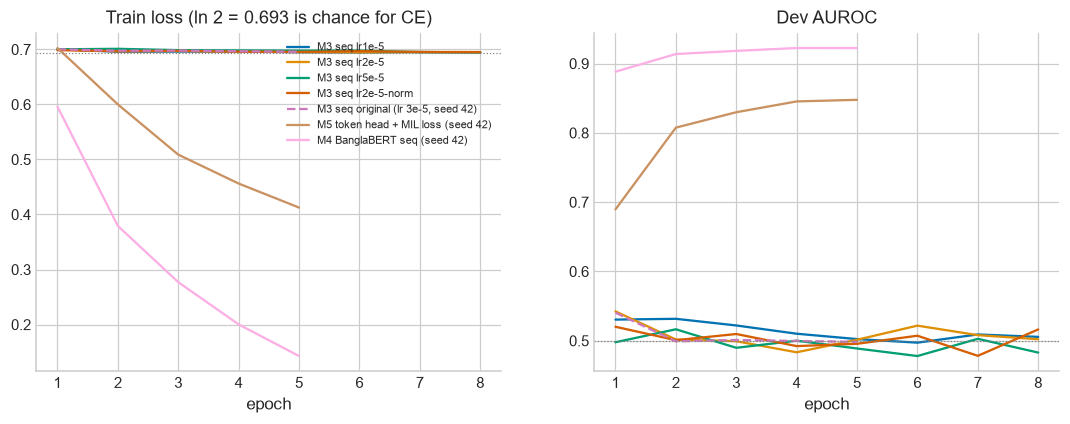

[figure] saved figX1_training_dynamics_xlmr_vs_banglabert.png/.pdf @300dpi


In [19]:
# X8 — Phase 1B (GPU): can XLM-R-base with a sequence-classification head learn this task at all?
#      seed 42, 8 epochs, NO early stopping (patience off), norm off (= M5 setting) except one variant; the recipe is chosen by DEV AUROC only.
M3_DIAG_SPECS = [("lr1e-5", 1e-5, False), ("lr2e-5", 2e-5, False), ("lr5e-5", 5e-5, False), ("lr2e-5-norm", 2e-5, True)]
M3_DIAG_EPOCHS = 8
M3_DIAG = {}

def run_m3(tag, lr, norm, seed):
    key = f"M3-100pct-diag-{tag}"; out = ckpt_dir(key, seed)
    train_model("seq", MODELS["XLM-R-base"], BH_TRAIN, BH_DEV, seed, out, max_len=512, norm_on=norm, use_query=True,
                epochs=M3_DIAG_EPOCHS, lr=lr, patience=999, min_epochs=999, tag=f"{key}_s{seed}")
    with Lazy(lambda: HFScorer(str(out), "seq", 512, norm, True), key=key) as lz:
        m, rd, rt_, tau = run_dev_test(key, seed, lz, BH_DEV, BH_TEST, "Y_dev", "Y_test")
    tl = json.loads((out / "train_log.json").read_text())
    pdv = np.array([r["pred_prob"] for r in rd])
    print(f"[1B] {key} seed={seed}: test F1={m['macro_f1']:.3f} AUROC={m['auroc']:.3f} | best dev AUROC={tl['best_dev']:.3f} | final loss={tl['log'][-1]['train_loss']:.3f} | dev-prob SD={pdv.std():.3f}")
    return dict(key=key, tag=tag, seed=seed, lr=lr, norm=norm, tau=tau, test=rt_, dev=rd, metrics=m, log=tl["log"], best_dev=float(tl["best_dev"]), dev_prob_sd=float(pdv.std()))

for tag, lr, norm in M3_DIAG_SPECS:
    res = _safe(f"1B M3 diag {tag}", lambda tag=tag, lr=lr, norm=norm: run_m3(tag, lr, norm, 42))
    if res is not None: M3_DIAG[tag] = res

rows = []
for tag, d in M3_DIAG.items():
    L = d["log"]; ep_best = int(np.argmax([x["dev_auroc"] for x in L])) + 1
    yt, pt = recs_arrays(d["test"])
    rows.append({"Setting": f"lr {d['lr']:.0e}, normaliser {'on' if d['norm'] else 'off'}", "Epochs": len(L), "Min train loss": round(min(x["train_loss"] for x in L), 3), "Final train loss": round(L[-1]["train_loss"], 3),
                 "Best dev AUROC": round(d["best_dev"], 3), "Epoch of best": ep_best, "Dev-prob SD": round(d["dev_prob_sd"], 3),
                 "Test F1 (dev tau*)": round(d["metrics"]["macro_f1"], 3), "Test F1 @0.5": round(macro_f1(yt, (pt >= 0.5).astype(int)), 3), "Test AUROC": round(d["metrics"]["auroc"], 3)})
def _log(path):
    try: return json.loads(Path(path).read_text())["log"]
    except Exception: return None
_o = _log(ckpt_dir("M3-100pct", 42) / "train_log.json")
if _o:
    yt, pt = recs_arrays(M3_OLD[0]["test"])
    rows.insert(0, {"Setting": "ORIGINAL run: lr 3e-5, normaliser off, early stopping (seed 42)", "Epochs": len(_o), "Min train loss": round(min(x["train_loss"] for x in _o), 3), "Final train loss": round(_o[-1]["train_loss"], 3),
                    "Best dev AUROC": round(max(x["dev_auroc"] for x in _o), 3), "Epoch of best": int(np.argmax([x["dev_auroc"] for x in _o])) + 1, "Dev-prob SD": float("nan"),
                    "Test F1 (dev tau*)": round(M3_OLD[0]["metrics"]["macro_f1"], 3), "Test F1 @0.5": round(macro_f1(yt, (pt >= 0.5).astype(int)), 3), "Test AUROC": round(M3_OLD[0]["metrics"]["auroc"], 3)})
if rows:
    T11 = pd.DataFrame(rows)
    save_table(T11, "table11_m3_diagnostic", "XLM-R-base with a sequence-classification head, seed 42, 8 epochs, no early stopping. A loss near ln 2 = 0.693 and a dev-probability SD near 0 mean the head predicts a constant (collapse).", higher_better=["Best dev AUROC", "Test AUROC"])
    display(T11)

# ---- if some recipe learned (decided on DEV AUROC only), complete it with the two other seeds ----
M3_NEW = []; M3_NEW_TAG = None
_learned = [d for d in M3_DIAG.values() if d["best_dev"] >= 0.65]
if _learned:
    best = max(_learned, key=lambda d: d["best_dev"]); M3_NEW_TAG = best["tag"]
    print(f"[1B] recipe '{M3_NEW_TAG}' learned (best dev AUROC {best['best_dev']:.3f}); training the remaining seeds with it")
    M3_NEW.append(best)
    for seed in [s for s in SEEDS if s != 42]:
        res = _safe(f"1B M3 {M3_NEW_TAG} seed {seed}", lambda seed=seed: run_m3(best["tag"], best["lr"], best["norm"], seed))
        if res is not None: M3_NEW.append(res)
    s_ = subset_stats(M3_NEW)
    print(f"[1B] M3 (XLM-R seq, recipe {M3_NEW_TAG}) over {len(M3_NEW)} seeds: Macro-F1 {s_['f1']:.3f} ± {s_['f1_sd']:.3f}, AUROC {s_['auroc']:.3f}")
elif not M3_DIAG:
    print("[1B] no diagnostic run completed (see FAILURES at the end) - re-run this cell.")
else:
    print("[1B] no recipe cleared dev AUROC 0.65 -> the sequence-classification XLM-R failure is confirmed under 4 matched recipes; M5 (token head) is the multilingual baseline.")

# ---- training dynamics figure: why does the MIL/token head learn while the sequence head does not? ----
curves = [(f"M3 seq {d['tag']}", d["log"], "-") for d in M3_DIAG.values()]
for lab, p, ls in [("M3 seq original (lr 3e-5, seed 42)", ckpt_dir("M3-100pct", 42) / "train_log.json", "--"), ("M5 token head + MIL loss (seed 42)", CKPT / "M5_mil_seed42" / "train_log.json", "-"),
                   ("M4 BanglaBERT seq (seed 42)", ckpt_dir("M4-100pct", 42) / "train_log.json", "-")]:
    lg = _log(p)
    if lg: curves.append((lab, lg, ls))
if curves:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, (lab, lg, ls) in enumerate(curves):
        ep = [x["epoch"] for x in lg]; ax[0].plot(ep, [x["train_loss"] for x in lg], ls, label=lab, color=PALETTE[i % len(PALETTE)]); ax[1].plot(ep, [x["dev_auroc"] for x in lg], ls, color=PALETTE[i % len(PALETTE)])
    ax[0].axhline(0.693, color="grey", lw=0.8, ls=":"); ax[0].set_title("Train loss (ln 2 = 0.693 is chance for CE)"); ax[0].set_xlabel("epoch")
    ax[1].axhline(0.5, color="grey", lw=0.8, ls=":"); ax[1].set_title("Dev AUROC"); ax[1].set_xlabel("epoch"); ax[0].legend(fontsize=7, loc="upper right")
    save_fig(fig, "figX1_training_dynamics_xlmr_vs_banglabert")


## Final tables, integrity check, summary

[table] saved table12b_context_split.csv/.tex (10 rows)


,Model,Input,Seeds,F1 all,F1 with context (n=718),CI with,AUROC with,F1 without context (n=510),CI without,AUROC without,Δ F1 (with − without)
0,M0 lexical,Q/C/A (rule-based),1,0.653 ± 0.000,0.779 ± 0.000,"[0.745, 0.808]",0.759,0.333 ± 0.000,"[0.314, 0.353]",0.500,0.446
1,M1 released EN,"Q+C+A, zero-shot",1,0.533 ± 0.000,0.575 ± 0.000,"[0.539, 0.612]",0.604,0.333 ± 0.000,"[0.314, 0.353]",0.544,0.242
2,M2 released EuroBERT-CN,"Q+C+A, zero-shot",1,0.508 ± 0.000,0.491 ± 0.000,"[0.455, 0.526]",0.520,0.390 ± 0.000,"[0.354, 0.428]",0.501,0.101
3,"M3 XLM-R seq (original, collapsed)",Q+C+A,3,0.502 ± 0.054,0.486 ± 0.029,"[0.463, 0.507]",0.544,0.432 ± 0.066,"[0.404, 0.460]",0.513,0.054
4,M4 BanglaBERT-large (reference),Q+C+A,3,0.832 ± 0.007,0.921 ± 0.006,"[0.902, 0.936]",0.983,0.705 ± 0.015,"[0.672, 0.736]",0.806,0.216
5,M5 XLM-R MIL token detector,Q+C+A,3,0.730 ± 0.008,0.854 ± 0.013,"[0.831, 0.877]",0.939,0.552 ± 0.033,"[0.519, 0.582]",0.576,0.302
6,"M4 8-bit, with question (seed 42)",Q+C+A,1,0.825 ± 0.000,0.921 ± 0.000,"[0.900, 0.941]",0.980,0.686 ± 0.000,"[0.645, 0.725]",0.783,0.235
7,"M4 8-bit, question dropped (seed 42)",C+A,1,0.735 ± 0.000,0.897 ± 0.000,"[0.873, 0.919]",0.971,0.504 ± 0.000,"[0.462, 0.547]",0.497,0.393
8,M4 answer-only (new),A,3,0.572 ± 0.004,0.607 ± 0.006,"[0.575, 0.636]",0.674,0.518 ± 0.004,"[0.482, 0.551]",0.528,0.089
9,"M4 question+answer, no context (new)",Q+A,3,0.703 ± 0.011,0.704 ± 0.016,"[0.676, 0.732]",0.808,0.700 ± 0.010,"[0.663, 0.734]",0.804,0.004


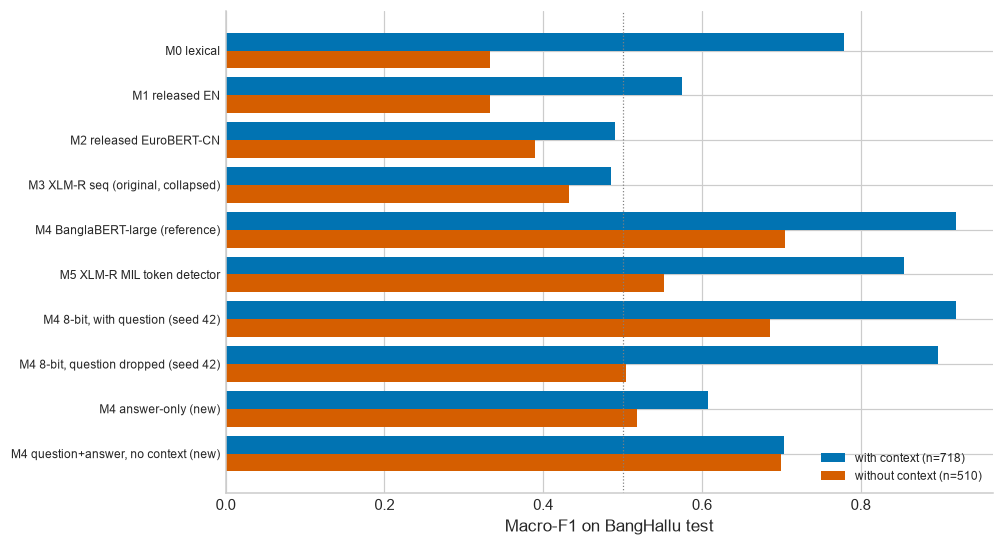

[figure] saved figX2_context_split.png/.pdf @300dpi
[table] saved table15_key_contrasts.csv/.tex (15 rows)


,Contrast,Subset,N,Δ Macro-F1,95% paired-bootstrap CI,CI excludes 0
0,M4 reference − M5 (XLM-R MIL),all test rows,1228,0.102,"[0.080, 0.124]",yes
1,M4 reference − M5 (XLM-R MIL),with context,718,0.066,"[0.046, 0.089]",yes
2,M4 reference − M5 (XLM-R MIL),without context,510,0.153,"[0.111, 0.193]",yes
3,M4 reference − M0 (lexical),all test rows,1228,0.179,"[0.151, 0.209]",yes
4,M4 reference − M0 (lexical),with context,718,0.141,"[0.112, 0.174]",yes
5,M4 reference − M0 (lexical),without context,510,0.372,"[0.332, 0.409]",yes
6,M5 − M0 (lexical),all test rows,1228,0.077,"[0.052, 0.103]",yes
7,M5 − M0 (lexical),with context,718,0.075,"[0.048, 0.106]",yes
8,M5 − M0 (lexical),without context,510,0.218,"[0.181, 0.253]",yes
9,M4 reference − M4 question+answer (no context),all test rows,1228,0.129,"[0.109, 0.150]",yes


[guard] original files changed or missing: none  (results/, tables/, predictions/ are untouched)
[done] results2/extended_summary.md and manifest_v2.json written.  Failures: none


In [20]:
# X9 — final tables that include the new GPU runs, integrity check, summary
CTX_MODELS_FINAL = dict(CTX_MODELS)
if GROUND["answeronly"]: CTX_MODELS_FINAL["M4 answer-only (new)"] = (GROUND["answeronly"], "A")
if GROUND["nocontext"]: CTX_MODELS_FINAL["M4 question+answer, no context (new)"] = (GROUND["nocontext"], "Q+A")
if M3_NEW: CTX_MODELS_FINAL[f"M3 XLM-R seq, matched recipe {M3_NEW_TAG} (new)"] = (M3_NEW, "Q+C+A")
T12B = context_split_table(CTX_MODELS_FINAL, "table12b_context_split", "BangHallu test split by availability of a context passage (all models, including the new ablation runs). Each model uses its own frozen tau*; CIs are seed-averaged paired bootstrap (1000 resamples).")

fig, ax = plt.subplots(figsize=(9, 0.42 * len(CTX_MODELS_FINAL) + 1.5)); labs = list(CTX_MODELS_FINAL); ypos = np.arange(len(labs))
w = [subset_stats(CTX_MODELS_FINAL[l][0], WITH_IDS, ci=False)["f1"] for l in labs]; wo = [subset_stats(CTX_MODELS_FINAL[l][0], WITHOUT_IDS, ci=False)["f1"] for l in labs]
ax.barh(ypos - 0.2, w, 0.4, label=f"with context (n={len(WITH_IDS)})", color=PALETTE[0]); ax.barh(ypos + 0.2, wo, 0.4, label=f"without context (n={len(WITHOUT_IDS)})", color=PALETTE[3])
ax.axvline(0.5, color="grey", lw=0.8, ls=":"); ax.set_yticks(ypos); ax.set_yticklabels(labs, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("Macro-F1 on BangHallu test"); ax.legend(fontsize=8, loc="lower right")
save_fig(fig, "figX2_context_split")

# ---- key paired contrasts (seed-averaged Macro-F1 difference, paired bootstrap CI) ----
_CON = [("M4 reference − M5 (XLM-R MIL)", STAGE4_M4, M5_RES), ("M4 reference − M0 (lexical)", STAGE4_M4, [FROZEN["M0"]]), ("M5 − M0 (lexical)", M5_RES, [FROZEN["M0"]]),
        ("M4 reference − M4 question+answer (no context)", STAGE4_M4, GROUND["nocontext"]), ("M4 reference − M4 answer-only", STAGE4_M4, GROUND["answeronly"])]
if M3_NEW: _CON.append(("M4 reference − M3 matched recipe", STAGE4_M4, M3_NEW))
_rows = []
for lab, A, B in _CON:
    if not A or not B: continue
    for sub_name, ids in (("all test rows", None), ("with context", WITH_IDS), ("without context", WITHOUT_IDS)):
        y, _, Ha = runs_arrays(A, ids); _, _, Hb = runs_arrays(B, ids)
        d = float(np.mean([macro_f1(y, h) for h in Ha]) - np.mean([macro_f1(y, h) for h in Hb])); lo, hi = paired_delta_ci(y, Ha, Hb)
        _rows.append({"Contrast": lab, "Subset": sub_name, "N": len(y), "Δ Macro-F1": round(d, 3), "95% paired-bootstrap CI": fmt_ci(lo, hi), "CI excludes 0": "yes" if (lo > 0 or hi < 0) else "no"})
T15 = pd.DataFrame(_rows); save_table(T15, "table15_key_contrasts", "Paired contrasts between the main models on BangHallu test (seed-averaged Macro-F1 differences, 1000 paired bootstrap resamples).", group_col="Contrast"); display(T15)

# ---- the original artifacts must be untouched ----
_changed = [p for p, fp in FINGERPRINTS.items() if (not Path(p).exists()) or _fp(Path(p)) != fp]
print("[guard] original files changed or missing:", _changed if _changed else "none  (results/, tables/, predictions/ are untouched)")

# ---- summary ----
S = ["# ProofBangla — extended analysis (auto-generated)", ""]
S += [f"* BangHallu test rows without any context: {len(WITHOUT_IDS)} of {len(BH_TEST)} ({100*len(WITHOUT_IDS)/len(BH_TEST):.1f}%)"]
for lab, (runs, _) in CTX_MODELS_FINAL.items():
    a, b = subset_stats(runs, WITH_IDS, ci=False), subset_stats(runs, WITHOUT_IDS, ci=False)
    S.append(f"  * {lab}: F1 with context {a['f1']:.3f} / without context {b['f1']:.3f}")
if GROUND["answeronly"] or GROUND["nocontext"]:
    S += ["", "## Grounding ablation (M4, 3 seeds)"]
    for k, v in GROUND.items():
        if v: s_ = subset_stats(v, ci=False); S.append(f"* {k}: Macro-F1 {s_['f1']:.3f} ± {s_['f1_sd']:.3f}, AUROC {s_['auroc']:.3f}")
S += ["", "## M3 diagnostic"] + [f"* {t}: best dev AUROC {d['best_dev']:.3f}, test F1 {d['metrics']['macro_f1']:.3f}" for t, d in M3_DIAG.items()]
if M3_NEW: s_ = subset_stats(M3_NEW, ci=False); S.append(f"* recipe {M3_NEW_TAG} over {len(M3_NEW)} seeds: Macro-F1 {s_['f1']:.3f} ± {s_['f1_sd']:.3f}")
if T12A is not None: S += ["", "## Olikbochon (leak-filtered)", T12A.to_string(index=False)]
S += ["", "## Temperature scaling", T12C.to_string(index=False), "", "## Split overlap", T14.to_string(index=False)]
S += ["", "## Failures", *(FAILURES if FAILURES else ["none"])]
(RES / "extended_summary.md").write_text("\n".join(S), encoding="utf-8")
(RES / "manifest_v2.json").write_text(json.dumps(dict(created=time.strftime("%Y-%m-%d %H:%M:%S"), python=sys.version.split()[0], torch=torch.__version__, gpu=torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    new_tables=sorted(p.name for p in TAB.glob("*.csv")), new_figures=sorted(p.name for p in FIG.glob("*.png")), failures=FAILURES, original_files_changed=_changed), indent=1))
print("[done] results2/extended_summary.md and manifest_v2.json written.  Failures:", FAILURES if FAILURES else "none")


## After manual annotation
Fill `manual_category` (1–10, legend in `results2/error_taxonomy_legend.csv`) for the 100 rows of `results2/error_analysis_banghallu_100_samples.csv`, **without opening the *_KEY_ file**, then run the next cell.

In [21]:
# X10 — run this cell ONLY AFTER you have filled 'manual_category' in results2/error_analysis_banghallu_100_samples.csv
from sklearn.metrics import cohen_kappa_score
_sheet = pd.read_csv(RES / "error_analysis_banghallu_100_samples.csv", encoding="utf-8-sig")
_key = pd.read_csv(RES / "error_analysis_banghallu_KEY_do_not_open_before_labelling.csv", encoding="utf-8-sig")
_col = [c for c in _sheet.columns if c.startswith("manual_category")][0]
_m = _sheet.merge(_key[["sample_id", "category", "category_name"]], on="sample_id")
_m[_col] = pd.to_numeric(_m[_col], errors="coerce"); _m = _m.dropna(subset=[_col])
if len(_m) < 20:
    print(f"Only {len(_m)} rows labelled so far - fill 'manual_category' (1-10) for all 100 rows first.")
else:
    agree = float((_m[_col].astype(int) == _m["category"].astype(int)).mean())
    kappa = float(cohen_kappa_score(_m["category"].astype(int), _m[_col].astype(int)))
    print(f"n={len(_m)}  raw agreement automatic vs manual = {agree:.1%}   Cohen's kappa = {kappa:.3f}")
    print(pd.crosstab(_m["category"].astype(int), _m[_col].astype(int), rownames=["auto"], colnames=["manual"]))
    pc = _m.groupby("category").apply(lambda g: float((g[_col].astype(int) == g["category"].astype(int)).mean())).round(2)
    print("per-category precision of the automatic tagger:\n", pc.to_string())


Only 0 rows labelled so far - fill 'manual_category' (1-10) for all 100 rows first.
